# Segmentación socio-sanitaria de los distritos de Madrid (caso 1.3) - cierre

Este notebook cierra el caso 1.3. Continúa el baseline exploratorio de `clustering_distritos.ipynb` (que queda como histórico) y hace tres cosas:

1. **Modelo base justificado y comparación de alternativas**: la elección de algoritmo y de *k* se hace por ensayo y error documentado (k-means y jerárquico Ward con k = 2…8, y DBSCAN como tercer candidato que sugiere el enunciado).
2. **Robustez**: qué aguanta la partición y qué no (semillas, distritos atípicos, imputaciones, variables).
3. **Análisis socioeconómico completo**: cruces entre las variables para responder a la pregunta del caso: entender cómo se distribuye Madrid, si los distritos más vulnerables tienen tipologías de emergencia distintas y qué se asocia a los tiempos de respuesta.

Todo se calcula sobre los CSV ya limpios del repositorio (`data_clean/` y las tablas de esta carpeta); aquí no se vuelve a limpiar nada. Marco honesto: son 21 distritos, así que todo el análisis es **exploratorio**; no se afirma significación estadística ni causalidad.

## 1. Carga y comprobaciones

Se cargan las tablas del caso y las activaciones limpias, y se comprueba antes de nada que cada distrito es quien dice ser (21 filas, id único, nombre coherente entre la tabla real y la normalizada) y que el escalado 0-1 del CSV sigue correspondiendo a los valores reales. Si algo no cuadrara, el notebook pararía aquí en vez de analizar datos mal unidos.

Para los análisis por distrito solo valen las filas de los 21 distritos oficiales: se dejan fuera 567 activaciones sin distrito (`NO CONSTA`, decisión ya tomada en la limpieza) y 34 fuera del término municipal o en carreteras de circunvalación.

In [1]:
%matplotlib inline
import json, os, urllib.request, urllib.parse
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import PathPatch
from matplotlib.path import Path as MPath
from matplotlib.colors import Normalize, to_rgb
from matplotlib import cm
from shapely.geometry import shape

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
raiz = carpeta if (carpeta / 'data_clean').is_dir() else carpeta / '..'
FIG = carpeta / 'graficos_cierre_9D'
FIG.mkdir(exist_ok=True)

def guarda(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches='tight')
    print('guardado:', FIG / nombre)

df = pd.read_csv(carpeta / 'tabla_distritos.csv')
nrm = pd.read_csv(carpeta / 'tabla_distritos_norm.csv')

# No unir por posición sin comprobar la identidad de cada distrito.
for nombre, tabla in [('real', df), ('normalizada', nrm)]:
    assert len(tabla) == 21, f'Tabla {nombre}: se esperan 21 distritos'
    assert tabla['distrito_id'].notna().all() and tabla['distrito_id'].is_unique
assert set(df.distrito_id) == set(nrm.distrito_id)
nrm = nrm.set_index('distrito_id').loc[df.distrito_id].reset_index()
assert df['distrito'].equals(nrm['distrito'])

print('Entradas utilizadas (SHA-256):')
for archivo in ['tabla_distritos.csv', 'tabla_distritos_norm.csv']:
    print(' ', archivo, hashlib.sha256((carpeta / archivo).read_bytes()).hexdigest()[:16], '…')

act = pd.read_csv(raiz / 'data_clean' / 'activaciones_limpio.csv')
cat = pd.read_csv(raiz / 'data_clean' / 'tipos_emergencia_clean.csv')
n_total = len(act)
act = act[act.distrito.isin(df.distrito)].copy()
print(f'\nActivaciones: {n_total:,} en total; {n_total - len(act):,} fuera de los 21 distritos '
      f'(NO CONSTA / fuera de término / circunvalaciones) -> quedan {len(act):,}'.replace(',', '.'))

# Cada activación hereda la categoría corregida del catálogo de tipos (la columna
# "categoria" original era poco fiable; la limpieza ya dejó la versión corregida).
act = act.merge(cat[['codigo', 'categoria_correcta']],
                left_on='tipo_emergencia', right_on='codigo', how='left')
assert act['codigo'].notna().all(), 'Hay tipos de emergencia sin correspondencia en el catálogo'
act['hora'] = pd.to_datetime(act.hora_solicitud, format='%H:%M:%S', errors='coerce').dt.hour
print('Activaciones sin hora válida (cuentan para demanda, no para franjas):', int(act.hora.isna().sum()))
print('\nTablas cargadas y comprobadas:', df.shape, nrm.shape, act.shape)
COLORES_C = {0: '#e07b39', 1: '#2f7fb8', 2: '#5aa454'}


Entradas utilizadas (SHA-256):
  tabla_distritos.csv e4d4125966f0f9bf …
  tabla_distritos_norm.csv f9c792f732ca8f4c …

Activaciones: 146.567 en total; 601 fuera de los 21 distritos (NO CONSTA / fuera de término / circunvalaciones) -> quedan 145.966


Activaciones sin hora válida (cuentan para demanda, no para franjas): 1407

Tablas cargadas y comprobadas: (21, 22) (21, 22) (145966, 16)


## 1.1 Decisiones cerradas, evidencia y trazabilidad

El análisis es definitivo **dentro de su alcance exploratorio**: definitivo no significa que conozcamos los valores ausentes ni causalidad. No hay solicitudes abiertas de confirmación al cliente. Se conservan raw y valores observados; cada estimación se etiqueta como tal.

|Decisión|Evidencia y comprobación|Límite|
|---|---|---|
|Corregir hospital 13 a Villa y hospital 8 a Moncloa|Direcciones oficiales consultadas 17/11/2026, tabla siguiente y limpieza_hospitales.ipynb|Ubicación del recurso, no residencia ni cobertura|
|No completar camas con otra serie|SERMAS2024, tabla 10; valores del catálogo difieren de instaladas 2024 y dos referencias agrupan centros|No afirmar capacidad homogénea ni sumar conocidos como total|
|No repartir unidades VALLECAS|IDs locales sin correspondencia verificable con directorio municipal|Base y cobertura no son equivalentes|
|NO CONSTA en activaciones ambiguas|Origen dice solo VALLECAS; unidad/hospital no identifican el lugar del aviso|39 es número de origen, no un subconjunto final contado aquí|
|Mantener 21 distritos con imputación social kNN3|Notebook de limpieza muestra vecinos; prueba sin 4 distritos afectados más abajo, ARI|La estabilidad de estas pruebas no convierte imputaciones en observaciones|
|No análisis diario ni meteo|CSV tiene año,mes,horas, no día ni clave compatible|No inventar fecha|
|Tasas por población residente|Tamaño de distritos distinto; se muestran conteos y denominador|Visitantes no medidos; no riesgo individual|
|Prioridad de catálogo|`prioridad` deriva de tipo en CSV limpio, no de triaje registrado por evento|Es mezcla de gravedad típica, no gravedad clínica observada|

La edad del paciente presenta un patrón de registro anómalo en la exploración. No se usa para explicar diferencias demográficas o clínicas. Se excluye edad_media_paciente del modelo principal 9D por prudencia interpretativa: el patrón no explicado y su influencia sobre los grupos hacen débil usarla para definir perfiles. No se excluye por un rango pequeño ni por buscar mejor silueta. Se conserva 10D como comparación ejecutada; se explican ventajas y contrapartidas de robustez en 7.9. pct_mayores_65 del censo se mantiene.

Fuentes oficiales: [Infanta Leonor](https://www.comunidad.madrid/hospital/infantaleonor/ciudadanos/llegar-contactar), [Jiménez Díaz](https://www.comunidad.madrid/centros/hospital-universitario-fundacion-jimenez-diaz), [SERMAS2024, tabla 10, p 31](https://gestiona3.madrid.org/bvirtual/BVCM051700.pdf), [bases municipales](https://www.madrid.es/portales/munimadrid/es/Inicio/El-Ayuntamiento/Villa-de-Vallecas/SAMUR-Proteccion-Civil/?idCapitulo=1231815&vgnextchannel=8291ca5d5fb96010VgnVCM100000dc0ca8c0RCRD&vgnextfmt=default&vgnextoid=c88fcdb1bfffa010VgnVCM100000d90ca8c0RCRD).


In [2]:
# Comprobaciones reproducibles de decisiones y entradas, sin modificar datos originales.
hospitales = pd.read_csv(raiz / 'data_clean/hospitales_limpio.csv')
assert hospitales.set_index('hospital_id').loc[13,'distrito'] == 'VILLA DE VALLECAS'
assert hospitales.set_index('hospital_id').loc[8,'distrito'] == 'MONCLOA-ARAVACA'
print(hospitales.loc[hospitales.hospital_id.isin([8,13]), ['hospital_id','nombre_corto','distrito','camas']].to_string(index=False))
print('Celdas vacías actuales por columna de oferta:')
print(df[['unidades_samur','num_hospitales_cat','camas_hospital']].isna().sum().to_string())
print('Tiempos: duración observada en minutos = intervención-solicitud, regla nocturna documentada en limpieza.')
print('Prioridad: mezcla de tipos según catálogo; no triaje observado.')

comparacion_camas=pd.DataFrame([
('La Paz',1328,1187,'Complejo La Paz-CarlosIII-Cantoblanco: perímetro distinto'),
('Gregorio Marañón',1500,1239,'Diferencia'),('Clínico San Carlos',961,861,'Diferencia'),
('12 de Octubre',1256,1161,'Diferencia'),('Ramón y Cajal',1092,877,'Diferencia'),
('La Princesa',480,533,'Diferencia'),('Puerta de Hierro',613,613,'Coincidencia numérica'),
('Getafe',560,543,'Diferencia'),('Severo Ochoa',425,386,'Diferencia'),
('Infanta Leonor',260,402,'Incluye Virgen de la Torre: perímetro distinto'),
('Henares',310,258,'Diferencia'),('Infanta Sofía',283,334,'Diferencia'),
('Infanta Cristina',213,188,'Diferencia'),('Gómez Ulla',500,475,'Diferencia')],
columns=['hospital','catalogo_sin_ano_definido','instaladas2024_SERMAS','comparabilidad'])
display(comparacion_camas)
print('Fuente: Memoria SERMAS2024, tabla10, p31/PDF32. Diferencia no equivale a error histórico.')
print('Beata María Ana:150 en catálogo frente a163 en ficha Ministerio sin año visible; no contraste2024.')


 hospital_id           nombre_corto          distrito  camas
           8 FUNDACION JIMENEZ DIAZ   MONCLOA-ARAVACA    NaN
          13         INFANTA LEONOR VILLA DE VALLECAS  260.0
Celdas vacías actuales por columna de oferta:
unidades_samur        2
num_hospitales_cat    0
camas_hospital        1
Tiempos: duración observada en minutos = intervención-solicitud, regla nocturna documentada en limpieza.
Prioridad: mezcla de tipos según catálogo; no triaje observado.


,hospital,catalogo_sin_ano_definido,instaladas2024_SERMAS,comparabilidad
0,La Paz,1328,1187,Complejo La Paz-CarlosIII-Cantoblanco: perímet...
1,Gregorio Marañón,1500,1239,Diferencia
2,Clínico San Carlos,961,861,Diferencia
3,12 de Octubre,1256,1161,Diferencia
4,Ramón y Cajal,1092,877,Diferencia
5,La Princesa,480,533,Diferencia
6,Puerta de Hierro,613,613,Coincidencia numérica
7,Getafe,560,543,Diferencia
8,Severo Ochoa,425,386,Diferencia
9,Infanta Leonor,260,402,Incluye Virgen de la Torre: perímetro distinto


Fuente: Memoria SERMAS2024, tabla10, p31/PDF32. Diferencia no equivale a error histórico.
Beata María Ana:150 en catálogo frente a163 en ficha Ministerio sin año visible; no contraste2024.


### 1.2 Diagnóstico de edad registrada: no equivale al censo

`paciente_edad` procede del CSV limpio de activaciones. La limpieza conserva edades válidas y pasa fuera de 0..115 a nulo: no genera ni imputa edades. La distribución casi uniforme 0..99 es un hecho del archivo, no prueba su causa. No se afirma anonimización ni datos sintéticos. El min-max aplicado a una media distrital de rango estrecho puede amplificar diferencias pequeñas. Se muestra el diagnóstico reproducible para decidir su papel en el modelo. `pct_mayores_65` procede del socioeconómico y describe residentes: es otra variable y otra fuente, no la edad de pacientes.


Edad registrada en activaciones distritales: n_total= 145966 n_validos= 145063 nulos= 903
Rango y valores únicos: 0.0 99.0 100
Conteos por edad min/max/media/desv: 1318 1514 1450.63 39.06085772305322
Rango de medias por distrito: 48.67 50.7
guardado: graficos_cierre_9D/18_diagnostico_edad_registrada.png


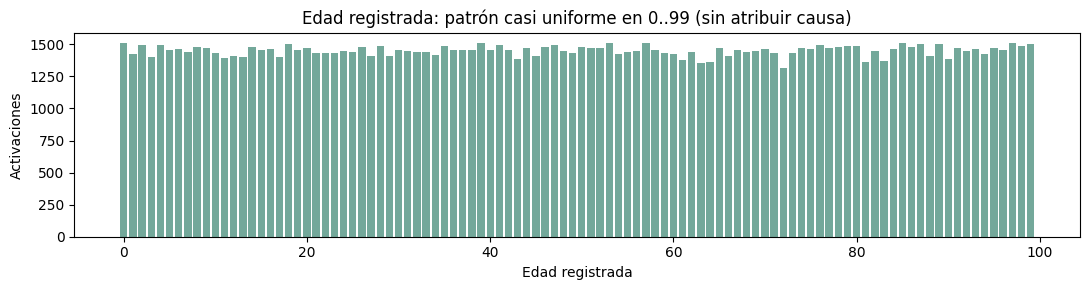

,distrito,edad_media_paciente,pct_mayores_65
0,CENTRO,50.07,22.1
1,ARGANZUELA,49.27,18.5
2,RETIRO,49.14,25.3
3,SALAMANCA,49.33,26.8
4,CHAMARTIN,49.02,25.2
5,TETUAN,49.94,17.8
6,CHAMBERI,49.49,23.5
7,FUENCARRAL-EL PARDO,49.52,16.2
8,MONCLOA-ARAVACA,49.07,19.8
9,LATINA,49.55,20.5


In [3]:
edades=act.paciente_edad
conteo_edades=edades.value_counts().sort_index()
print('Edad registrada en activaciones distritales:', 'n_total=',len(edades), 'n_validos=',edades.notna().sum(), 'nulos=',edades.isna().sum())
print('Rango y valores únicos:',edades.min(),edades.max(),edades.nunique())
print('Conteos por edad min/max/media/desv:',conteo_edades.min(),conteo_edades.max(),conteo_edades.mean(),conteo_edades.std())
print('Rango de medias por distrito:',df.edad_media_paciente.min(),df.edad_media_paciente.max())
fig,ax=plt.subplots(figsize=(11,3));ax.bar(conteo_edades.index,conteo_edades,color='#73a89a');ax.set(xlabel='Edad registrada',ylabel='Activaciones',title='Edad registrada: patrón casi uniforme en 0..99 (sin atribuir causa)');fig.tight_layout();guarda(fig,'18_diagnostico_edad_registrada.png');plt.show()
display(df[['distrito','edad_media_paciente','pct_mayores_65']])


## 2. Selección de variables para el clustering

Criterios de selección del modelo principal 9D, en este orden. Además de las reglas siguientes se excluye edad_media_paciente por el diagnóstico 1.2 y la comparación 7.9; no se altera el archivo de activaciones ni el censo.

1. **Fuera las 3 columnas de oferta** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): decisión definitiva del alcance. Las unidades carecen de distrito demostrable en 15 filas; las camas no tienen año/definición común verificados; contar hospitales de catálogo no mide capacidad operativa. Los perfiles se definen con contexto y servicio y la oferta se analiza aparte con bases conocidas. Las dos correcciones geográficas y su evidencia se auditan a continuación; no se imputan recursos.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debe decidir cómo se agrupan los distritos por su perfil socio-sanitario.
3. **Fuera las redundantes por construcción**: `poblacion` y `superficie_km2` (se prefiere densidad a tamaño absoluto) y `n_activaciones` (ya está en `activaciones_por_1000hab`, comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí** (|r| > 0,85): con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se queda una representante por grupo: `renta_media_hogar` (eje económico) y `pct_mayores_65` (eje edad), por ser las más directas de explicar.


#### Escalado de las variables para K-Means

Las variables seleccionadas mezclan euros, porcentajes, habitantes y minutos. K-Means asigna los grupos por distancias euclídeas: sin escalar, una variable con rango numérico mayor podría pesar mucho más en la distancia aunque no sea conceptualmente más importante. Se usa min-max por variable para llevar los valores a `[0, 1]` en `tabla_distritos_norm.csv`. Esto iguala los rangos, no decide pesos ni corrige redundancia; por eso la selección de variables correlacionadas se justifica aparte. En la celda siguiente se recalcula el min-max desde los datos reales, se compara con el CSV (tolerancia de 0,000051 por el redondeo a cuatro decimales) y se comprueba que la matriz `X` sea finita y esté en `[0, 1]` antes de entrar a K-Means.

El mapa de calor de abajo enseña **todas las combinaciones de variables** de la tabla, no solo las candidatas, para que la regla 4 se pueda auditar de un vistazo.

guardado: graficos_cierre_9D/00_correlacion_todas_las_variables.png


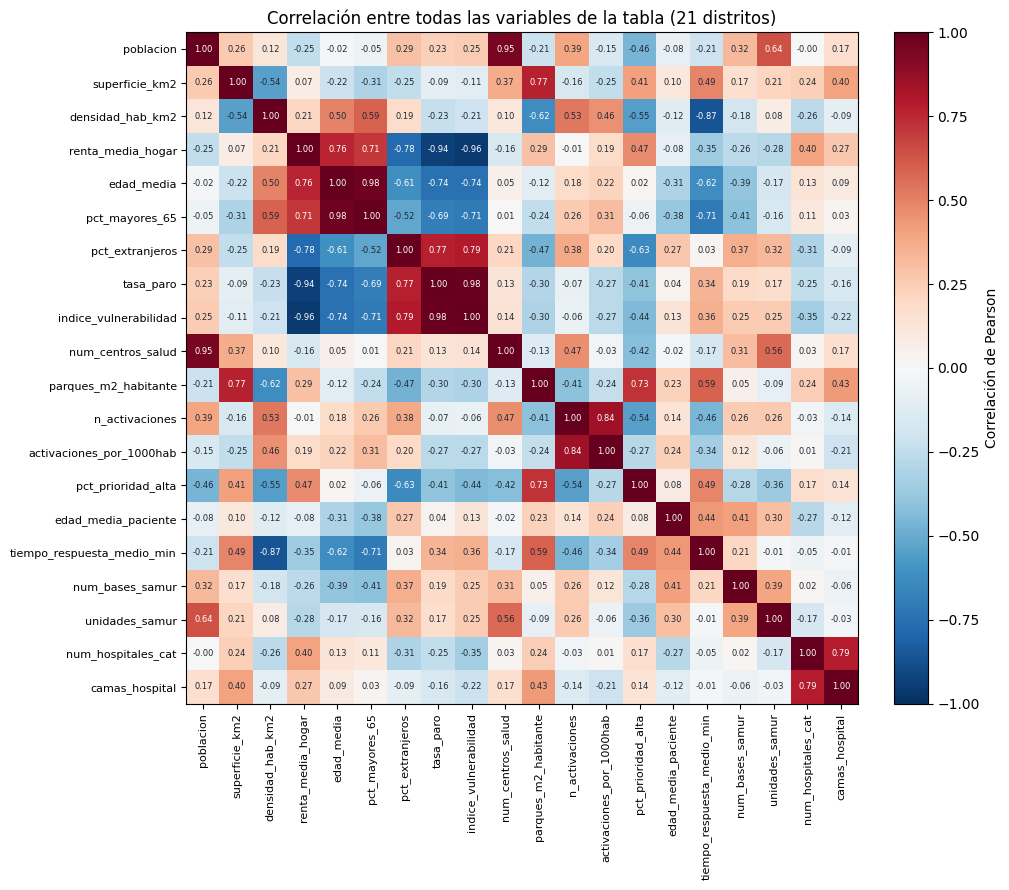

Pares de candidatas con |r| > 0,85 (regla 4):
  densidad_hab_km2 ~ tiempo_respuesta_medio_min: r = 0.87
  renta_media_hogar ~ tasa_paro: r = 0.94
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.96
  edad_media ~ pct_mayores_65: r = 0.98
  tasa_paro ~ indice_vulnerabilidad: r = 0.98

Variables finales del clustering (9):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - tiempo_respuesta_medio_min

Matriz del clustering sin huecos: (21, 9)


In [4]:
numericas = [c for c in df.columns if c not in ('distrito_id', 'distrito')]
corr = df[numericas].corr()

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numericas))); ax.set_yticks(range(len(numericas)))
ax.set_xticklabels(numericas, rotation=90, fontsize=8)
ax.set_yticklabels(numericas, fontsize=8)
for i in range(len(numericas)):
    for j in range(len(numericas)):
        v = corr.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=6,
                color='white' if abs(v) > 0.6 else '#1f2933')
fig.colorbar(im, fraction=0.046, pad=0.04, label='Correlación de Pearson')
ax.set_title('Correlación entre todas las variables de la tabla (21 distritos)')
fig.tight_layout()
guarda(fig, '00_correlacion_todas_las_variables.png')
plt.show()

candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
cc = df[candidatas].corr().abs()
print('Pares de candidatas con |r| > 0,85 (regla 4):')
for i, a in enumerate(candidatas):
    for b in candidatas[i+1:]:
        if cc.loc[a, b] > 0.85:
            print(f'  {a} ~ {b}: r = {cc.loc[a, b]:.2f}')

variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
variables = [v for v in variables if v != 'edad_media_paciente']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

# Comprobar que el CSV normalizado sigue correspondiendo a los valores reales
# (el cruce guarda cuatro decimales: tolerancia de medio último decimal).
recalculada = (df[variables] - df[variables].min()) / (df[variables].max() - df[variables].min())
assert np.allclose(recalculada, nrm[variables], atol=0.000051, rtol=0), 'Escalado desactualizado'
X = nrm[variables].to_numpy()
assert np.isfinite(X).all() and ((X >= 0) & (X <= 1)).all().all()
print('\nMatriz del clustering sin huecos:', X.shape)

`renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). `densidad_hab_km2` y `tiempo_respuesta_medio_min` (r = -0,87) se conservan las dos porque miden cosas distintas del caso (geografía del distrito frente a servicio prestado); la sensibilidad a esta decisión se mide en la sección de robustez.

## 3. Elección de algoritmo y de k (ensayo y error)

Se prueban los dos algoritmos que sugiere el enunciado más el jerárquico:

- **K-means** con k = 2…8 (codo por inercia y silueta).
- **Jerárquico Ward** con k = 2…8 (silueta).
- **DBSCAN** se evalúa con la rejilla ampliada de la sección 3.1. Se reportan grupos, ruido y tamaños para todas las configuraciones; se prefiere k-means para resumir todos los distritos, sin afirmar que DBSCAN sea inválido en general.

Para elegir k se miran tres cosas: la silueta, que el codo deje de bajar fuerte y que los grupos sean accionables para el caso (perfiles distintos con los que planificar).

guardado: graficos_cierre_9D/01_eleccion_de_k.png


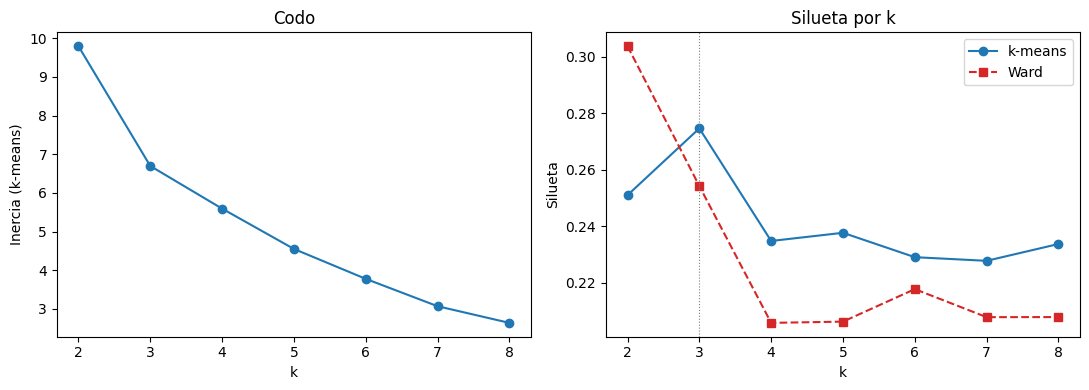

 k  inercia  silueta_kmeans  silueta_ward
 2      9.8           0.251         0.304
 3      6.7           0.275         0.254
 4      5.6           0.235         0.206
 5      4.5           0.238         0.206
 6      3.8           0.229         0.218
 7      3.1           0.228         0.208
 8      2.6           0.234         0.208

Prueba de DBSCAN (rejilla):
  eps=0.3, min_samples=2: 0 grupos, 21 puntos de ruido
  eps=0.3, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.4, min_samples=2: 3 grupos, 15 puntos de ruido
  eps=0.4, min_samples=3: 0 grupos, 21 puntos de ruido
  eps=0.5, min_samples=2: 4 grupos, 11 puntos de ruido
  eps=0.5, min_samples=3: 2 grupos, 15 puntos de ruido
  eps=0.6, min_samples=2: 3 grupos, 6 puntos de ruido
  eps=0.6, min_samples=3: 2 grupos, 8 puntos de ruido
  eps=0.7, min_samples=2: 1 grupos, 3 puntos de ruido
  eps=0.7, min_samples=3: 1 grupos, 3 puntos de ruido

Qué hace cada k candidata (k-means):
  k=2:
   - Centro + Arganzuela + Retiro + Salamanc

In [5]:
ks = range(2, 9)
inercias, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(list(ks), inercias, 'o-', color='#1f77b4')
ax1.set_xlabel('k'); ax1.set_ylabel('Inercia (k-means)'); ax1.set_title('Codo')
ax2.plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax2.plot(list(ks), sil_hc, 's--', label='Ward', color='#d62728')
ax2.axvline(3, color='grey', lw=0.8, ls=':')
ax2.set_xlabel('k'); ax2.set_ylabel('Silueta'); ax2.set_title('Silueta por k'); ax2.legend()
fig.tight_layout()
guarda(fig, '01_eleccion_de_k.png')
plt.show()

print(pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 1),
                    'silueta_kmeans': np.round(sil_km, 3), 'silueta_ward': np.round(sil_hc, 3)}).to_string(index=False))

print('\nPrueba de DBSCAN (rejilla):')
for eps in (0.3, 0.4, 0.5, 0.6, 0.7):
    for ms in (2, 3):
        lab = DBSCAN(eps=eps, min_samples=ms).fit(X).labels_
        print(f'  eps={eps}, min_samples={ms}: {len(set(lab) - {-1})} grupos, {(lab == -1).sum()} puntos de ruido')

print('\nQué hace cada k candidata (k-means):')
for k in (2, 3, 4):
    lab = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X).labels_
    grupos = [' + '.join(df.distrito.str.title()[lab == c]) for c in range(k)]
    print(f'  k={k}:')
    for g in grupos:
        print('   -', g)

### 3.1 DBSCAN: rejilla y evidencia del descarte

Se prueba la misma matriz 9D min-max y distancia euclídea: `eps=0,2...1,2` (paso 0,1) y `min_samples=2...5`, incluyendo puntos propios como define sklearn. No se comparan siluetas de una partición completa con otra que descarta gran parte de los distritos como ruido. Se muestran **todos** los resultados de esta rejilla, no solo la configuración peor. El rango amplía el ensayo inicial 0,3...0,7. La distancia ordenada al vecino de orden `min_samples` ayuda a leer las escalas, sin fijar un eps óptimo automático. DBSCAN admite ruido; no es un error del algoritmo. Se evalúa si ofrece perfiles multigrupo razonables y estables para resumir los 21 distritos. Ninguna rejilla prueba que DBSCAN sea inútil en cualquier parametrización o escalado.


,eps,min_samples,grupos,ruido,tamanos,silueta_sin_ruido
0,0.2,2,0,21,[],NaN
1,0.3,2,0,21,[],NaN
2,0.4,2,3,15,"[2, 2, 2]",0.539
3,0.5,2,4,11,"[2, 3, 3, 2]",0.397
4,0.6,2,3,6,"[10, 3, 2]",0.390
5,0.7,2,1,3,[18],NaN
6,0.8,2,1,2,[19],NaN
7,0.9,2,1,1,[20],NaN
8,1.0,2,1,1,[20],NaN
9,1.1,2,1,0,[21],NaN


guardado: graficos_cierre_9D/14_dbscan_rejilla_completa.png


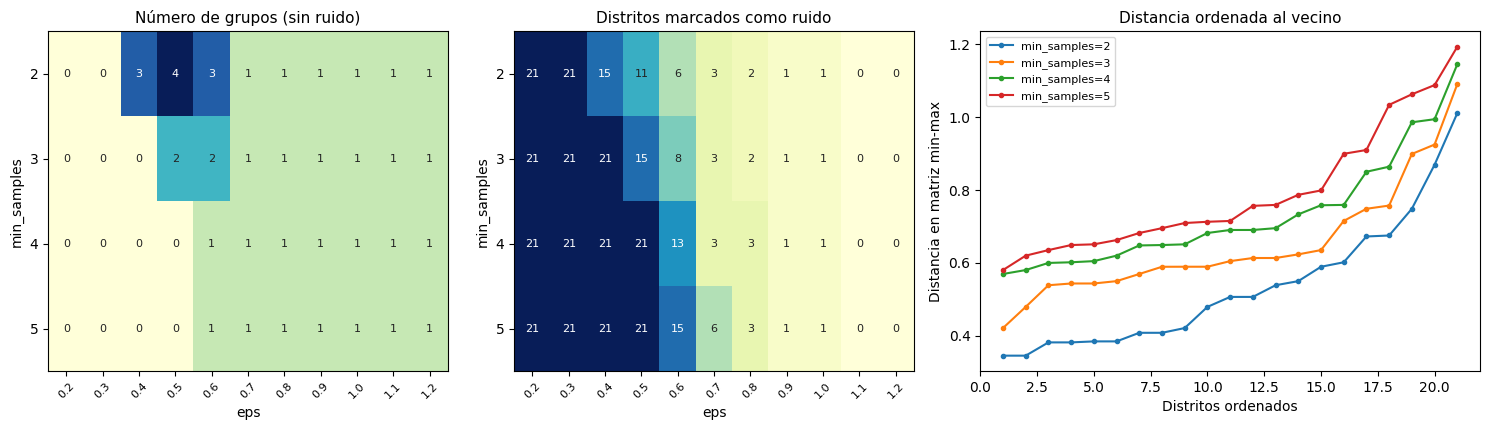

Configuraciones multigrupo sin ruido en esta rejilla: 0 de 44
Configuraciones con2+ grupos: 5
 eps  min_samples  grupos  ruido      tamanos
 0.4            2       3     15    [2, 2, 2]
 0.5            2       4     11 [2, 3, 3, 2]
 0.6            2       3      6   [10, 3, 2]
 0.5            3       2     15       [3, 3]
 0.6            3       2      8      [10, 3]


In [6]:
from sklearn.neighbors import NearestNeighbors
rejilla=[]
for ms in [2,3,4,5]:
    for eps in np.round(np.arange(.2,1.21,.1),2):
        labels=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X)
        ids=sorted(set(labels)-{-1}); sizes=[int((labels==c).sum()) for c in ids]
        good=labels!=-1
        sil=float(silhouette_score(X[good], labels[good])) if len(ids)>=2 and good.sum()>len(ids) else np.nan
        rejilla.append(dict(eps=eps,min_samples=ms,grupos=len(ids),ruido=int((~good).sum()),tamanos=str(sizes),silueta_sin_ruido=sil))
dbscan_pruebas=pd.DataFrame(rejilla)
display(dbscan_pruebas.round(3))
fig,axes=plt.subplots(1,3,figsize=(15,4.4),gridspec_kw={'width_ratios':[1,1,1.25]})
for ax,var,title in zip(axes[:2],['grupos','ruido'],['Número de grupos (sin ruido)','Distritos marcados como ruido']):
    mat=dbscan_pruebas.pivot(index='min_samples',columns='eps',values=var)
    ax.imshow(mat,cmap='YlGnBu',aspect='auto',vmin=0)
    ax.set_xticks(range(len(mat.columns)));ax.set_xticklabels([f'{v:.1f}' for v in mat.columns],rotation=45,fontsize=8)
    ax.set_yticks(range(4));ax.set_yticklabels(mat.index);ax.set_xlabel('eps');ax.set_ylabel('min_samples');ax.set_title(title,fontsize=11)
    for i in range(4):
        for j in range(len(mat.columns)):
            ax.text(j,i,str(mat.iloc[i,j]),ha='center',va='center',fontsize=8,color='white' if mat.iloc[i,j]>mat.to_numpy().max()*.55 else '#222')
for ms in [2,3,4,5]:
    dist,_=NearestNeighbors(n_neighbors=ms).fit(X).kneighbors(X)
    axes[2].plot(range(1,22),np.sort(dist[:,-1]),marker='.',label=f'min_samples={ms}')
axes[2].set_title('Distancia ordenada al vecino',fontsize=11);axes[2].set_xlabel('Distritos ordenados');axes[2].set_ylabel('Distancia en matriz min-max');axes[2].legend(fontsize=8)
fig.tight_layout();guarda(fig,'14_dbscan_rejilla_completa.png');plt.show()
completas=dbscan_pruebas.query('grupos >= 2 and ruido == 0')
print('Configuraciones multigrupo sin ruido en esta rejilla:',len(completas),'de',len(dbscan_pruebas))
print('Configuraciones con2+ grupos:',len(dbscan_pruebas.query('grupos >= 2')))
print(dbscan_pruebas.query('grupos >= 2')[['eps','min_samples','grupos','ruido','tamanos']].to_string(index=False))


**Lectura de la rejilla 9D:**5 de 44 configuraciones producen 2+grupos y dejan 6..15 distritos como ruido. Ninguna multigrupo incluye los 21 distritos. Las siluetas de puntos no ruido no se comparan como si cubrieran toda la ciudad. Se prefiere KMeans para resumir todos los distritos; no se declara DBSCAN inválido para otras tareas o parámetros.

**Lectura y elección:** k 3 es la mayor silueta KMeans ensayada(0,2747); k 4 baja a 0,2349. Ward k 2 alcanza 0,3038 pero ofrece una división menos detallada de perfiles sociales. El codo es gradual. Se elige KMeans k 3 por balance de separación modesta e interpretación social, no por máximo universal entre algoritmos. La silueta no prueba validez externa.

## 4. Modelo principal 9D y perfiles

In [7]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = pd.Series(km.labels_).map({0:1,1:0,2:2}).to_numpy()  # solo renombrar etiquetas, no reasignar distritos

# Los nombres salen de la tabla de perfiles de abajo, no al revés.
nombres = {0: 'Denso y vulnerable', 1: 'Acomodado y envejecido', 2: 'Periférico y disperso'}
df['cluster_nombre'] = df.cluster.map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f'Cluster {c} - {nombres[c]} ({len(d)} distritos, '
          f'{int(d.n_activaciones.sum()):,} activaciones, {d.n_activaciones.sum() / df.n_activaciones.sum() * 100:.0f}% del total):'.replace(',', '.'))
    print('  ', ', '.join(d.distrito.str.title()))

cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA 21 DISTRITOS'] = df[cols_desc].mean().round(2)
print('\nPerfil de cada grupo (valores reales, no normalizados):')
print(perfil.to_string())

Cluster 0 - Denso y vulnerable (9 distritos. 83.261 activaciones. 57% del total):
   Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde
Cluster 1 - Acomodado y envejecido (5 distritos. 29.203 activaciones. 20% del total):
   Retiro, Salamanca, Chamartin, Chamberi, Moratalaz
Cluster 2 - Periférico y disperso (7 distritos. 33.502 activaciones. 23% del total):
   Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa De Vallecas, Vicalvaro, San Blas-Canillejas, Barajas

Perfil de cada grupo (valores reales, no normalizados):
                        renta_media_hogar  tasa_paro  indice_vulnerabilidad  pct_mayores_65  pct_extranjeros  densidad_hab_km2  activaciones_por_1000hab  pct_prioridad_alta  edad_media_paciente  tiempo_respuesta_medio_min
cluster_nombre                                                                                                                                                                                         

guardado: graficos_cierre_9D/02_perfil_de_los_grupos.png


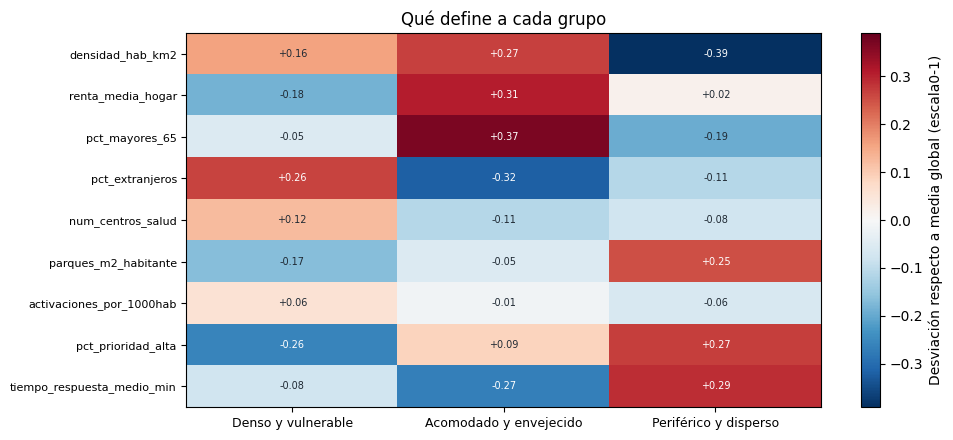

In [8]:
# Qué variable hace distinto a cada grupo: media normalizada del grupo menos media global
med_global = nrm[variables].mean()
dif = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean() - med_global

fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(dif.T, cmap='RdBu_r', vmin=-np.abs(dif.to_numpy()).max(),
               vmax=np.abs(dif.to_numpy()).max(), aspect='auto')
fig.colorbar(im, label='Desviación respecto a media global (escala0-1)')
ax.set_xticks(range(k_final)); ax.set_xticklabels([nombres[c] for c in range(k_final)], fontsize=9)
ax.set_yticks(range(len(variables))); ax.set_yticklabels(variables, fontsize=8)
for i in range(len(variables)):
    for j in range(k_final):
        ax.text(j, i, f'{dif.T.to_numpy()[i, j]:+.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(dif.T.to_numpy()[i, j]) > 0.25 else '#1f2933')
ax.set_title('Qué define a cada grupo')
fig.tight_layout()
guarda(fig, '02_perfil_de_los_grupos.png')
plt.show()

### 4.1 ¿Qué distritos encajan mejor? Silueta individual

La silueta compara distancia media al propio grupo (`a`) con la menor distancia media a otro (`b`): `(b-a)/max(a,b)`. Cercana a 1 indica mejor separación, alrededor de 0 una frontera y negativa mayor proximidad media a otro grupo. Se calcula en **las mismas 9 variables min-max**, no en el PCA2D. La media reproduce la silueta global; no es validación externa. Un distrito con silueta negativa no prueba que esté mal asignado ni exige moverlo a mano.


guardado: graficos_cierre_9D/15_silueta_por_distrito.png


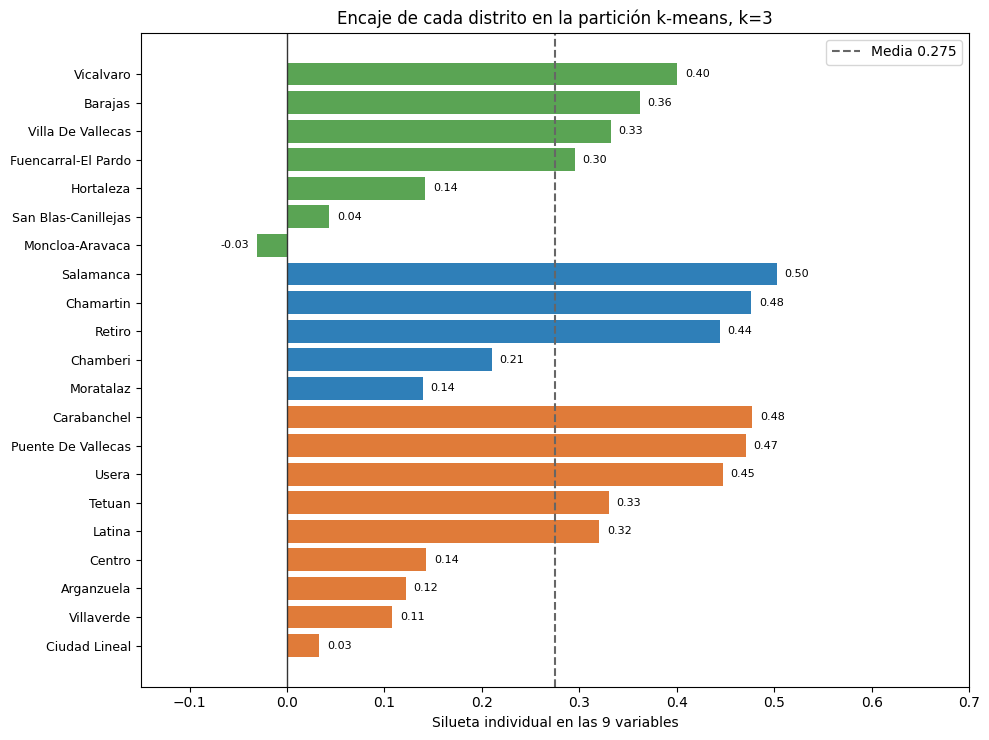

,distrito,cluster,cluster_nombre,silueta
14,CIUDAD LINEAL,0,Denso y vulnerable,0.033
16,VILLAVERDE,0,Denso y vulnerable,0.108
1,ARGANZUELA,0,Denso y vulnerable,0.122
0,CENTRO,0,Denso y vulnerable,0.143
9,LATINA,0,Denso y vulnerable,0.320
5,TETUAN,0,Denso y vulnerable,0.330
11,USERA,0,Denso y vulnerable,0.447
12,PUENTE DE VALLECAS,0,Denso y vulnerable,0.471
10,CARABANCHEL,0,Denso y vulnerable,0.477
13,MORATALAZ,1,Acomodado y envejecido,0.139


Siluetas negativas: ['MONCLOA-ARAVACA']


In [9]:
from sklearn.metrics import silhouette_samples
siluetas = df[['distrito','cluster','cluster_nombre']].copy()
siluetas['silueta']=silhouette_samples(X,df.cluster)
assert np.isclose(siluetas.silueta.mean(),silhouette_score(X,df.cluster))
siluetas=siluetas.sort_values(['cluster','silueta'])
fig,ax=plt.subplots(figsize=(10,7.5))
ax.barh(range(21),siluetas.silueta,color=[COLORES_C[c] for c in siluetas.cluster])
ax.set_yticks(range(21));ax.set_yticklabels(siluetas.distrito.str.title(),fontsize=9)
ax.axvline(0,color='#333',lw=1);ax.axvline(siluetas.silueta.mean(),ls='--',color='#666',label=f'Media {siluetas.silueta.mean():.3f}')
for i,v in enumerate(siluetas.silueta):ax.text(v+(.008 if v>=0 else -.008),i,f'{v:.2f}',ha='left' if v>=0 else 'right',va='center',fontsize=8)
ax.set_xlim(min(-.15,siluetas.silueta.min()-.1),max(.7,siluetas.silueta.max()+.1));ax.set_xlabel('Silueta individual en las 9 variables');ax.set_title('Encaje de cada distrito en la partición k-means, k=3');ax.legend()
fig.tight_layout();guarda(fig,'15_silueta_por_distrito.png');plt.show()
display(siluetas.round(3))
print('Siluetas negativas:',siluetas.loc[siluetas.silueta<0,'distrito'].tolist())


**Lectura individual 9D:** Moncloa-Aravaca es el único negativo(-0,030); Ciudad Lineal(0,033) y San Blas(0,043) están en frontera. Salamanca(0,503) y Carabanchel(0,477) están mejor separados en esta representación. Media 0,2747: separación modesta. Se conserva asignación del algoritmo, sin mover distritos a mano.

**Perfiles principales 9D:** denso y vulnerable 9 distritos,83.261 activaciones(57,0%); acomodado y envejecido 5 distritos,29.203(20,0%); periférico y disperso 7 distritos,33.502(23,0%). El perfil acomodado tiene 24,72%residentes mayores 65; los otros 18,10% y 15,93%. Es edad del censo, no edad de pacientes.

## 5. El mapa de Madrid por grupos

guardado: graficos_cierre_9D/03_mapa_grupos.png


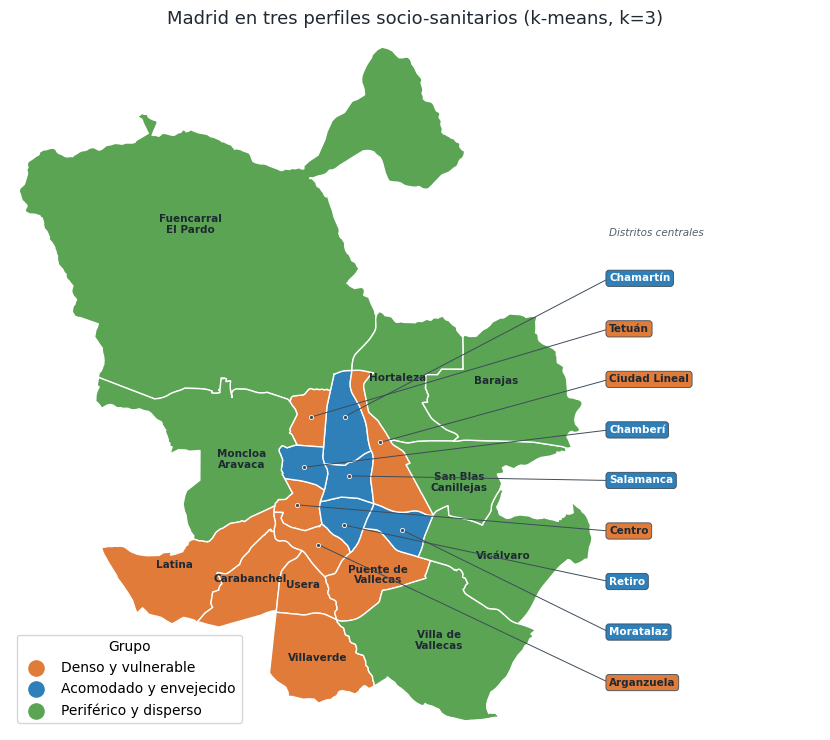

In [10]:
# Límites oficiales: servicio de mapas del Ayuntamiento de Madrid, capa DISTRITOS (ETRS89 / UTM 30N)
URL = ('https://sigma.madrid.es/hosted/rest/services/CARTOGRAFIA/LIMITES_ADMINISTRATIVOS/MapServer/3/query?'
       + urllib.parse.urlencode({'where': '1=1', 'outFields': 'COD_DIS_TX,NOMBRE', 'outSR': 25830, 'f': 'geojson'}))
if not (carpeta / 'distritos_madrid.geojson').exists():
    urllib.request.urlretrieve(URL, carpeta / 'distritos_madrid.geojson')
g = json.load(open(carpeta / 'distritos_madrid.geojson'))
geo = {int(f['properties']['COD_DIS_TX']): (shape(f['geometry']), f['properties']['NOMBRE']) for f in g['features']}
assert sorted(geo) == sorted(df.distrito_id), 'Los códigos del mapa no coinciden con la tabla'

t = df.copy(); t['cod'] = t.distrito_id
t['nombre'] = t.cod.map(lambda c: geo[c][1])
short = {'Fuencarral - El Pardo': 'Fuencarral\nEl Pardo', 'Moncloa - Aravaca': 'Moncloa\nAravaca',
         'San Blas - Canillejas': 'San Blas\nCanillejas', 'Puente de Vallecas': 'Puente de\nVallecas',
         'Villa de Vallecas': 'Villa de\nVallecas', 'Ciudad Lineal': 'Ciudad\nLineal'}
t['lab'] = t.nombre.map(lambda n: short.get(n, n))
INK = '#1f2933'
CORE = [1, 2, 3, 4, 5, 6, 7, 14, 15]

def lum(c):
    r, g_, b = to_rgb(c); return .299 * r + .587 * g_ + .114 * b

def patch(poly, fc, lw=1.0, ec='white'):
    verts, codes = [], []
    for ring in [poly.exterior] + list(poly.interiors):
        xy = np.array(ring.coords)
        verts += list(xy); codes += [MPath.MOVETO] + [MPath.LINETO] * (len(xy) - 2) + [MPath.CLOSEPOLY]
    return PathPatch(MPath(verts, codes), fc=fc, ec=ec, lw=lw)

def draw(ax, colors, labels=None, fs=7.5, txtcol=None, ifs=7.5):
    for _, r in t.iterrows():
        ax.add_patch(patch(geo[r.cod][0], colors[r.cod]))
    b = [geo[c][0].bounds for c in geo]
    x0 = min(x[0] for x in b); y0 = min(x[1] for x in b)
    x1 = max(x[2] for x in b); y1 = max(x[3] for x in b); w = x1 - x0
    ax.set_xlim(x0 - 500, x1 + 0.40 * w); ax.set_ylim(y0 - 500, y1 + 500)
    ax.set_aspect('equal'); ax.axis('off')
    if labels is None:
        return
    for c in [c for c in geo if c not in CORE]:
        p = geo[c][0].representative_point()
        col = colors[c]
        ax.text(p.x, p.y, labels[c], ha='center', va='center', fontsize=fs,
                color=(txtcol[c] if txtcol else ('white' if lum(col) < .5 else INK)),
                fontweight='bold', linespacing=1.05)
    ys = {c: geo[c][0].representative_point() for c in CORE}
    order = sorted(CORE, key=lambda c: -ys[c].y)
    yc = np.mean([p.y for p in ys.values()]); span = (y1 - y0) * 0.075
    xs = x1 + 0.03 * w
    ax.text(xs, yc + (len(order) / 2) * span + span * .3, 'Distritos centrales',
            fontsize=ifs, color='#52606d', ha='left', va='bottom', style='italic')
    for k, c in enumerate(order):
        yy = yc + (len(order) / 2 - k - 0.5) * span
        p = ys[c]
        ax.plot([p.x, xs], [p.y, yy], color='#3e4c59', lw=.7, zorder=5, solid_capstyle='round')
        ax.plot(p.x, p.y, 'o', ms=3, color='#3e4c59', zorder=6, mec='white', mew=.6)
        col = colors[c]; tcol = ('white' if lum(col) < .5 else INK)
        ax.text(xs, yy, labels[c].replace('\n', ' '), ha='left', va='center', fontsize=ifs,
                fontweight='bold', color=tcol, zorder=7,
                bbox=dict(boxstyle='round,pad=0.3', fc=col, ec='#3e4c59', lw=.6))

COLORES_C = {0: '#e07b39', 1: '#2f7fb8', 2: '#5aa454'}
fig, ax = plt.subplots(figsize=(11, 7.5))
colores = {r.cod: COLORES_C[r.cluster] for _, r in t.iterrows()}
draw(ax, colores, labels=dict(zip(t.cod, t.lab)))
for c in range(3):
    ax.scatter([], [], color=COLORES_C[c], s=120, label=f'{nombres[c]}')
ax.legend(loc='lower left', fontsize=10, frameon=True, title='Grupo', title_fontsize=10)
ax.set_title('Madrid en tres perfiles socio-sanitarios (k-means, k=3)', fontsize=13, color=INK, pad=10)
fig.tight_layout()
guarda(fig, '03_mapa_grupos.png')
plt.show()

guardado: graficos_cierre_9D/04_dendrograma_y_pca.png


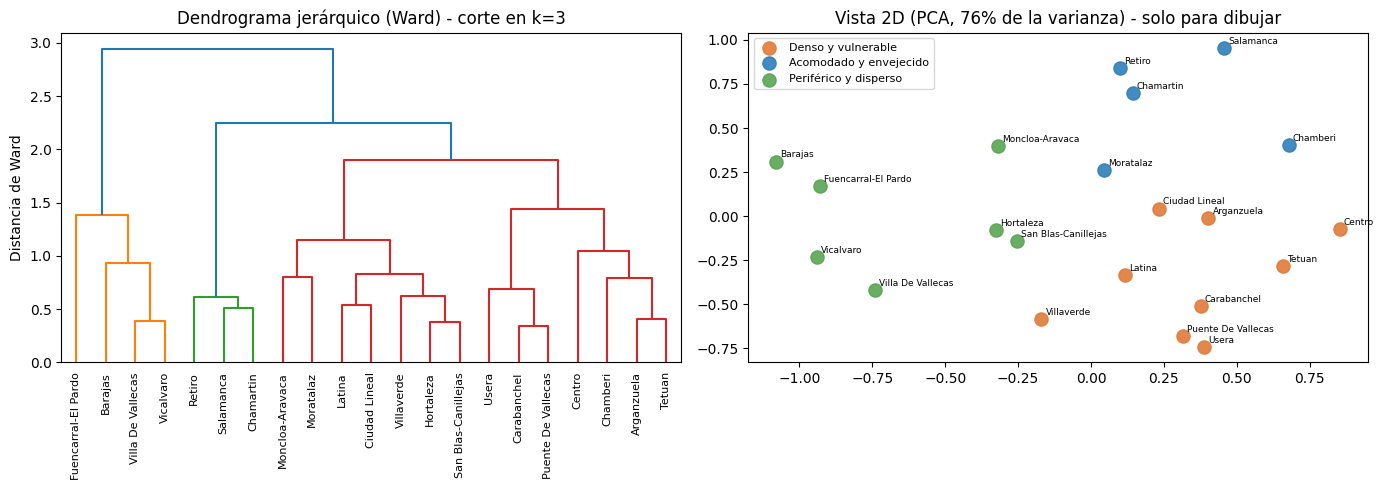

Varianza explicada PCA2D: [0.43172487 0.32393415] acumulada: 0.7556590166000411
PCA solo visualiza: clusters calculados en matriz9D principal min-max; no en los2 componentes.


In [11]:
# Dendrograma Ward y vista 2D (PCA): dos formas de ver la misma estructura
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
Z = linkage(X, method='ward')
dendrogram(Z, labels=df.distrito.str.title().tolist(), leaf_rotation=90, ax=ax1,
           color_threshold=Z[-(k_final - 1), 2], leaf_font_size=8)
ax1.set_title('Dendrograma jerárquico (Ward) - corte en k=3'); ax1.set_ylabel('Distancia de Ward')

pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    ax2.scatter(P[m, 0], P[m, 1], s=90, color=COLORES_C[c], label=nombres[c], alpha=0.9)
for i, r in df.iterrows():
    ax2.annotate(r.distrito.title(), (P[i, 0], P[i, 1]), fontsize=6.5,
                 xytext=(3, 3), textcoords='offset points')
ax2.set_title(f'Vista 2D (PCA, {pca.explained_variance_ratio_.sum() * 100:.0f}% de la varianza) - solo para dibujar')
ax2.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '04_dendrograma_y_pca.png')
plt.show()
print('Varianza explicada PCA2D:',pca.explained_variance_ratio_, 'acumulada:',pca.explained_variance_ratio_.sum())
print('PCA solo visualiza: clusters calculados en matriz9D principal min-max; no en los2 componentes.')


## 6. Robustez: qué aguanta y qué no

Antes de sacar conclusiones, varias pruebas sobre la partición k = 3:

- **Otras 19 semillas** de k-means: ¿el resultado depende del azar del arranque?
- **Sin Centro**: distrito atípico (su tasa de activaciones por habitante es aproximadamente el doble de la del segundo).
- **Sin los 4 distritos con celdas imputadas** en las variables usadas (Retiro, Ciudad Lineal, Chamartín, San Blas-Canillejas).
- **Sin `renta_media_hogar` ni `pct_mayores_65`**: las dos variables con más peso social del modelo.
- **Ward en vez de k-means**: ¿otro algoritmo ve la misma estructura?

Se mide con ARI (1 = misma partición salvo el nombre de las etiquetas, 0 = acuerdo esperado por azar).

In [12]:
res = {}
aris = []
for seed in range(1, 20):
    lab = KMeans(n_clusters=3, n_init=50, random_state=seed).fit(X).labels_
    aris.append(adjusted_rand_score(df.cluster, lab))
res['19 semillas distintas'] = f'ARI mín {min(aris):.2f} / mediano {np.median(aris):.2f}'

mA = df.distrito != 'CENTRO'
kmA = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mA.to_numpy()])
res['Sin Centro'] = f'ARI {adjusted_rand_score(df.loc[mA, "cluster"], kmA.labels_):.2f}'

afectados = ['RETIRO', 'CIUDAD LINEAL', 'CHAMARTIN', 'SAN BLAS-CANILLEJAS']
mB = ~df.distrito.isin(afectados)
kmB = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mB.to_numpy()])
res['Sin los 4 con imputaciones'] = f'ARI {adjusted_rand_score(df.loc[mB, "cluster"], kmB.labels_):.2f}'

vars_sin = [v for v in variables if v not in ('renta_media_hogar', 'pct_mayores_65')]
kmS = KMeans(n_clusters=3, n_init=50, random_state=42).fit(nrm[vars_sin].to_numpy())
res['Sin renta ni % >65'] = f'ARI {adjusted_rand_score(df.cluster, kmS.labels_):.2f}'

hc3 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit(X)
res['Ward en vez de k-means'] = f'ARI {adjusted_rand_score(df.cluster, hc3.labels_):.2f}'

for k, v in res.items():
    print(f'{k:32s} {v}')
print('Comparación con Ward: ver ARI y tabla, sin asumir fronteras iguales.')
print('Coincidencia parcial entre estos métodos, no validación externa.')
print('Sensibilidad a variables de interpretación delicada (mismo k=3, escalado fijo):')
for quitar in ['densidad_hab_km2','tiempo_respuesta_medio_min','edad_media_paciente']:
    vv=[v for v in variables if v!=quitar]
    lab=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(nrm[vv].to_numpy())
    print(f'Sin {quitar}: ARI={adjusted_rand_score(df.cluster,lab):.3f}')


19 semillas distintas            ARI mín 1.00 / mediano 1.00
Sin Centro                       ARI 1.00
Sin los 4 con imputaciones       ARI 0.59
Sin renta ni % >65               ARI 0.73
Ward en vez de k-means           ARI 0.33
Comparación con Ward: ver ARI y tabla, sin asumir fronteras iguales.
Coincidencia parcial entre estos métodos, no validación externa.
Sensibilidad a variables de interpretación delicada (mismo k=3, escalado fijo):
Sin densidad_hab_km2: ARI=0.608
Sin tiempo_respuesta_medio_min: ARI=1.000
Sin edad_media_paciente: ARI=1.000


**Sensibilidad 9D:** retirar densidad da ARI0,608; retirar tiempo 1,000. La excepción a la regla de correlación densidad-tiempo se mantiene porque geografía y servicio representan conceptos distintos del enunciado, pero no se afirma independencia de sus pesos. La comparación 10D/9D aparece en 7.9.

**Robustez 9D:** ARI1,000 en 19 semillas y sin Centro;0,593 sin 4 distritos imputados;0,733 sin renta ni mayores 65;0,331 con Ward. La elección de variables y la muestra importan. No se vende estabilidad universal ni validación externa; las diferencias por grupo describen esta partición.

## 7. Cómo se distribuye Madrid: el análisis socioeconómico

Los mapas y cruces siguientes responden al enunciado por distrito, sin inferencia individual.

guardado: graficos_cierre_9D/05_mapas_variables.png


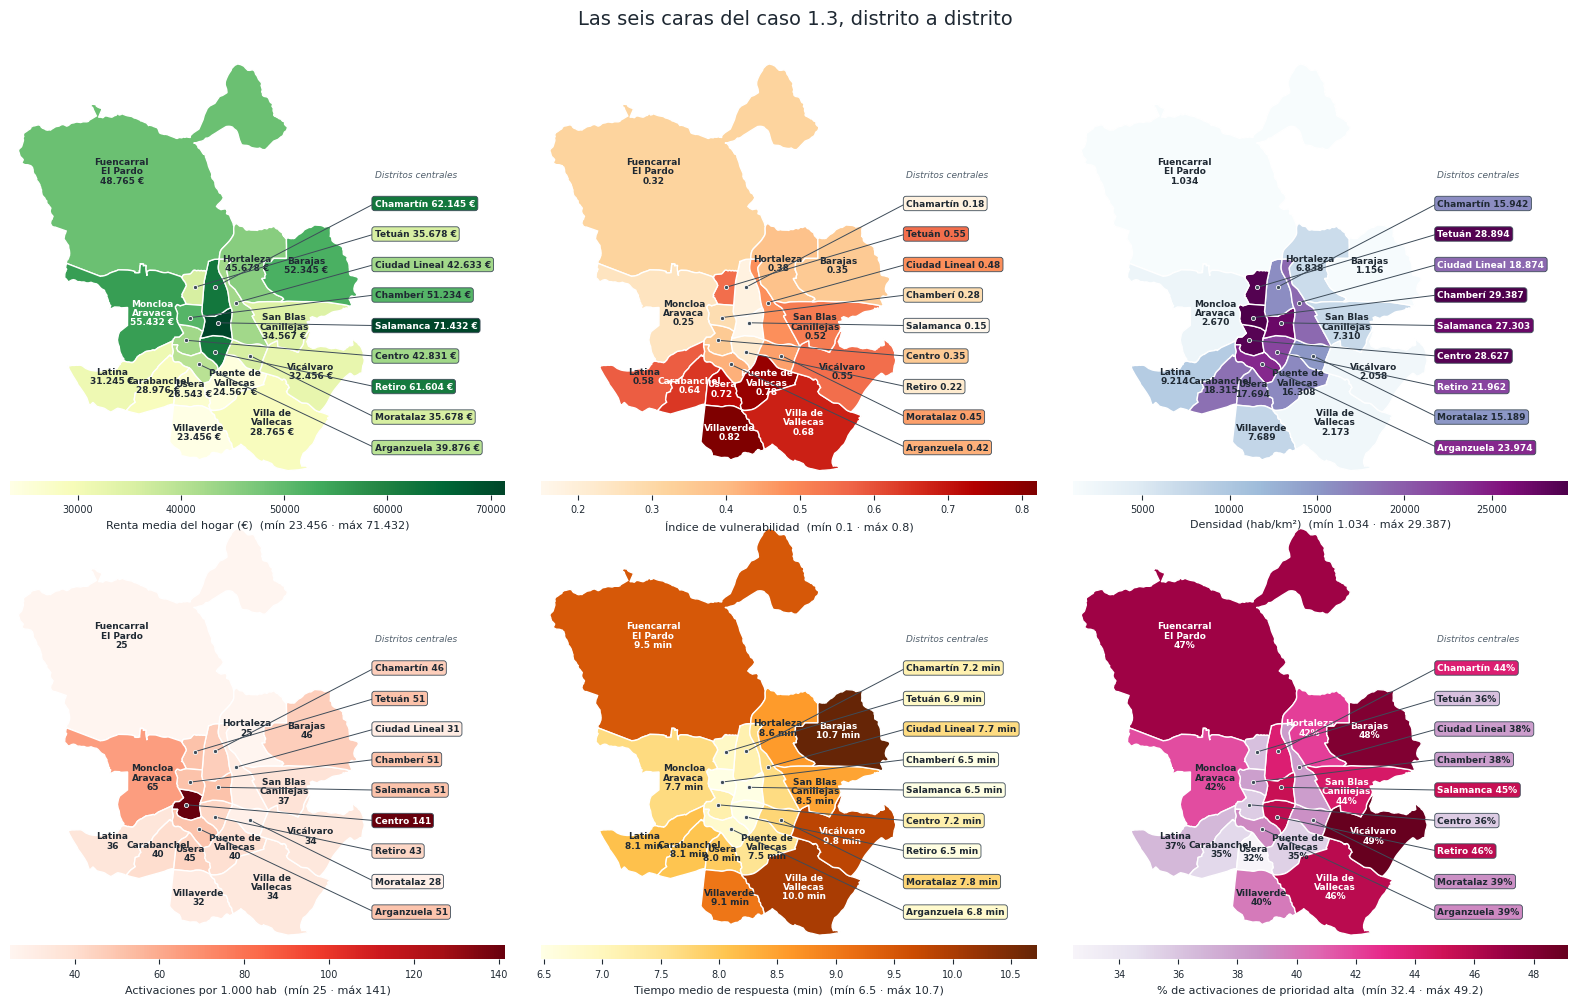

In [13]:
def choro(var, cmap, fmt):
    n = Normalize(t[var].min(), t[var].max())
    col = {r.cod: cmap(n(r[var])) for _, r in t.iterrows()}
    lab = {r.cod: r.lab + '\n' + fmt(r[var]) for _, r in t.iterrows()}
    tc = {c: ('white' if lum(col[c]) < .5 else INK) for c in col}
    return n, col, lab, tc

def cbar(fig, ax, n, cmap, label):
    sm = cm.ScalarMappable(norm=n, cmap=cmap)
    cb = fig.colorbar(sm, ax=ax, orientation='horizontal', fraction=.035, pad=.01, aspect=35)
    fm = (lambda x: f'{x:,.0f}'.replace(',', '.')) if n.vmax > 100 else (lambda x: f'{x:.1f}')
    cb.set_label(label + f'  (mín {fm(n.vmin)} · máx {fm(n.vmax)})', fontsize=8, color=INK)
    cb.ax.tick_params(labelsize=7, colors=INK); cb.outline.set_visible(False)

paneles = [
    ('renta_media_hogar', plt.get_cmap('YlGn'), lambda v: f'{v:,.0f} €'.replace(',', '.'), 'Renta media del hogar (€)'),
    ('indice_vulnerabilidad', plt.get_cmap('OrRd'), lambda v: f'{v:.2f}', 'Índice de vulnerabilidad'),
    ('densidad_hab_km2', plt.get_cmap('BuPu'), lambda v: f'{v:,.0f}'.replace(',', '.'), 'Densidad (hab/km²)'),
    ('activaciones_por_1000hab', plt.get_cmap('Reds'), lambda v: f'{v:.0f}', 'Activaciones por 1.000 hab'),
    ('tiempo_respuesta_medio_min', plt.get_cmap('YlOrBr'), lambda v: f'{v:.1f} min', 'Tiempo medio de respuesta (min)'),
    ('pct_prioridad_alta', plt.get_cmap('PuRd'), lambda v: f'{v:.0f}%', '% de activaciones de prioridad alta'),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (var, cmap, fmt, label) in zip(axes.flat, paneles):
    n, col, lab, tc = choro(var, cmap, fmt)
    draw(ax, col, labels=lab, txtcol=tc, fs=6.5, ifs=6.5)
    cbar(fig, ax, n, cmap, label)
fig.suptitle('Las seis caras del caso 1.3, distrito a distrito', fontsize=14, color=INK, y=1.00)
fig.tight_layout()
guarda(fig, '05_mapas_variables.png')
plt.show()

Los mapas ya cuentan la historia: la renta cae del noroeste al sureste, la vulnerabilidad hace justo el camino contrario, y la demanda por habitante se concentra en el centro. Los tiempos de respuesta crecen hacia el anillo exterior.

### 7.1 Lo que más y lo que menos se asocia al tiempo de respuesta

guardado: graficos_cierre_9D/06_densidad_vs_tiempo.png


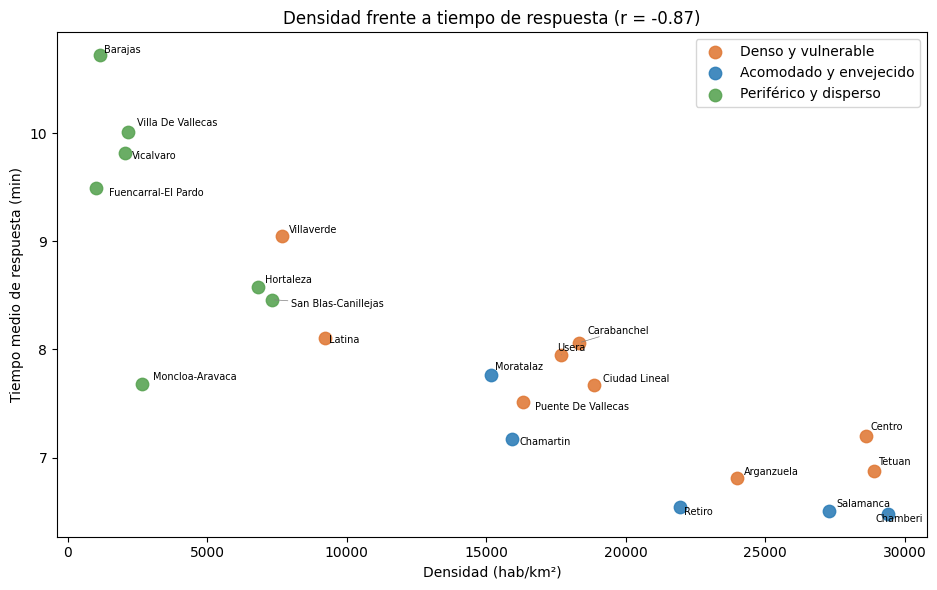

Correlación de cada variable con el tiempo medio de respuesta:
densidad_hab_km2           -0.87
pct_mayores_65             -0.71
edad_media                 -0.62
n_activaciones             -0.46
renta_media_hogar          -0.35
activaciones_por_1000hab   -0.34
poblacion                  -0.21
num_centros_salud          -0.17
num_hospitales_cat         -0.05
camas_hospital             -0.01
unidades_samur             -0.01
pct_extranjeros             0.03
num_bases_samur             0.21
tasa_paro                   0.34
indice_vulnerabilidad       0.36
edad_media_paciente         0.44
superficie_km2              0.49
pct_prioridad_alta          0.49
parques_m2_habitante        0.59


In [14]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.densidad_hab_km2, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax.text(r.densidad_hab_km2, r.tiempo_respuesta_medio_min,r.distrito.title(),fontsize=7))
from adjustText import adjust_text
np.random.seed(42)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_val = df[['densidad_hab_km2', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax.set_xlabel('Densidad (hab/km²)'); ax.set_ylabel('Tiempo medio de respuesta (min)')
ax.set_title(f'Densidad frente a tiempo de respuesta (r = {r_val:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '06_densidad_vs_tiempo.png')
plt.show()

corr_t = df[numericas].corr().tiempo_respuesta_medio_min.drop('tiempo_respuesta_medio_min').sort_values()
print('Correlación de cada variable con el tiempo medio de respuesta:')
print(corr_t.round(2).to_string())

### 7.1 b Respuesta: mediana, cola lenta y datos ausentes

La media puede ocultar una cola de registros lentos. Se añade mediana y percentil 90 de `tiempo_de_respuesta`, con interpolación lineal de pandas, por distrito del aviso. P90 es el valor por debajo del que queda aproximadamente 90% de los registros con tiempo válido; no garantía de servicio ni umbral clínico. Se muestran `n_total`, `n_valido`, faltantes y su porcentaje. Los nulos no se reemplazan por 0 ni se eliminan de la demanda. Se conservan todos los tiempos válidos según la limpieza aprobada, incluidos extremos: se muestran mínimo/máximo/P99 para auditar su efecto, sin recorte arbitrario. Si la falta de tiempo no es aleatoria, los cuantiles de válidos no representan todo el servicio.


,n_total,n_valido,mediana,p90,p99,media,minimo,maximo,faltantes,pct_faltante
distrito,,,,,,,,,,
BARAJAS,2210,1926,10.00,16.80,26.02,10.72,0.0,42.8,284,12.85
VICALVARO,2481,2249,9.00,15.20,26.80,9.82,0.0,96.7,232,9.35
FUENCARRAL-EL PARDO,6099,5465,8.90,14.70,24.81,9.49,0.0,74.5,634,10.40
VILLA DE VALLECAS,3805,3390,9.50,14.40,24.01,10.01,0.0,55.8,415,10.91
VILLAVERDE,4943,4423,8.60,14.20,22.00,9.05,0.0,53.4,520,10.52
SAN BLAS-CANILLEJAS,6080,5533,7.70,13.48,23.20,8.46,0.0,86.9,547,9.00
HORTALEZA,4832,4385,8.20,13.40,22.45,8.58,0.0,57.6,447,9.25
LATINA,8314,7478,7.45,13.40,20.10,8.11,0.0,83.2,836,10.06
MONCLOA-ARAVACA,7995,7238,7.00,13.00,22.56,7.68,0.0,66.0,757,9.47


guardado: graficos_cierre_9D/16_mediana_p90_respuesta.png


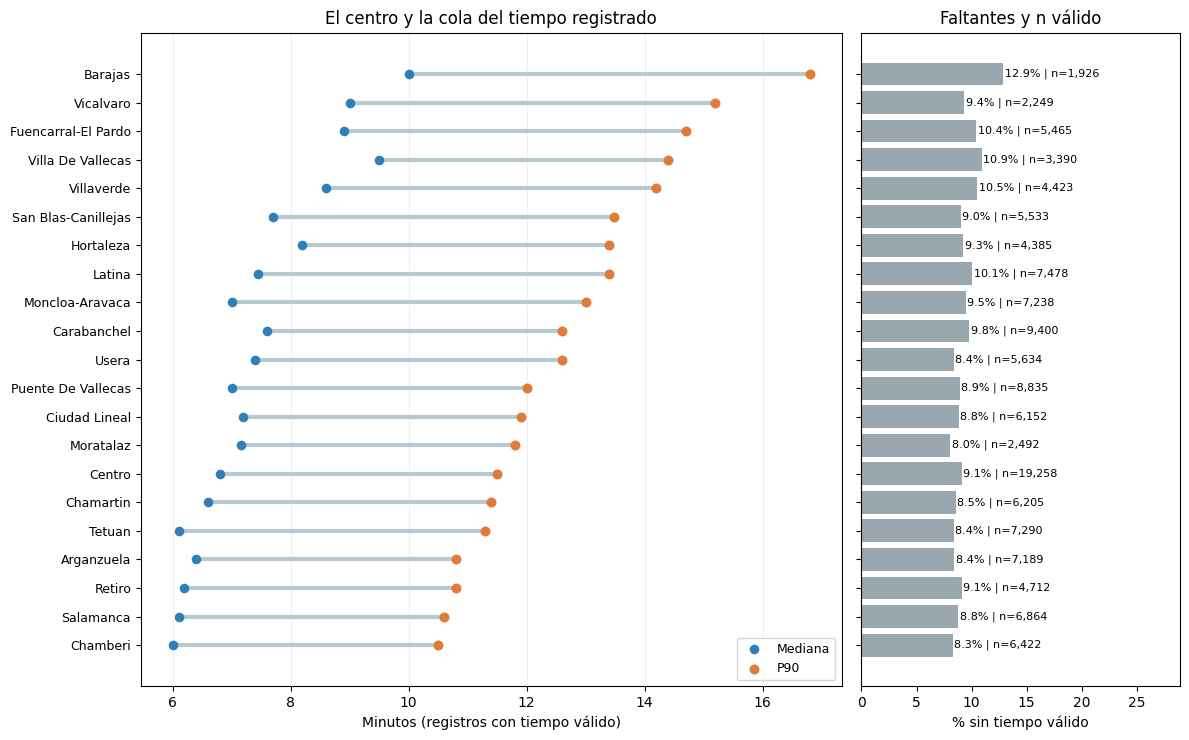

Total válido: 132540 sin tiempo: 13426


In [15]:
tiempo=pd.to_numeric(act['tiempo_de_respuesta'],errors='coerce')
assert not tiempo.dropna().lt(0).any(), 'Duración negativa sin tratar'
tiempos=act.assign(_tiempo=tiempo).groupby('distrito').agg(n_total=('activacion_id','size'),n_valido=('_tiempo','count'),mediana=('_tiempo','median'),p90=('_tiempo',lambda s:s.quantile(.9,interpolation='linear')),p99=('_tiempo',lambda s:s.quantile(.99,interpolation='linear')),media=('_tiempo','mean'),minimo=('_tiempo','min'),maximo=('_tiempo','max'))
tiempos['faltantes']=tiempos.n_total-tiempos.n_valido;tiempos['pct_faltante']=tiempos.faltantes/tiempos.n_total*100
assert tiempos.n_total.sum()==len(act)
assert np.allclose(tiempos['media'].reindex(df.distrito),df.tiempo_respuesta_medio_min,atol=.0051)
display(tiempos.sort_values('p90',ascending=False).round(2))
q=tiempos.sort_values('p90');y=np.arange(len(q))
fig,(ax,axn)=plt.subplots(1,2,figsize=(12,7.5),gridspec_kw={'width_ratios':[2.2,1]},sharey=True)
ax.hlines(y,q.mediana,q.p90,color='#b8c9d0',lw=3);ax.scatter(q.mediana,y,s=35,color='#2f7fb8',label='Mediana',zorder=3);ax.scatter(q.p90,y,s=38,color='#e07b39',label='P90',zorder=3)
ax.set_yticks(y);ax.set_yticklabels(q.index.str.title(),fontsize=9);ax.set_xlabel('Minutos (registros con tiempo válido)');ax.set_title('El centro y la cola del tiempo registrado');ax.legend(loc='lower right',fontsize=9);ax.grid(axis='x',alpha=.2)
axn.barh(y,q.pct_faltante,color='#9aa7ae');axn.set_xlabel('% sin tiempo válido');axn.set_title('Faltantes y n válido');axn.set_xlim(0,max(q.pct_faltante)*2.25)
for i,(_,v) in enumerate(q.iterrows()):axn.text(v.pct_faltante+.15,i,f'{v.pct_faltante:.1f}% | n={int(v.n_valido):,}',fontsize=8,va='center')
fig.tight_layout();guarda(fig,'16_mediana_p90_respuesta.png');plt.show()
print('Total válido:',int(tiempos.n_valido.sum()),'sin tiempo:',int(tiempos.faltantes.sum()))


**Lectura de tiempos:** Chamberí tiene mediana 6,0 y P90=10,5 min; Barajas 10,0 y 16,8 min. La diferencia se observa tanto en el centro como en la cola de la distribución registrada, no solo en medias. Entre distritos, faltan 8,0%-12,9% de tiempos; en Barajas son 284 de 2210(12,85%) y en Chamberí 579 de 7001(8,27%). En total hay 136.635 tiempos válidos y 9.331 faltantes entre 145.966 activaciones distritales. El mayor P90 no se puede atribuir causalmente a renta, bases o geografía ni comparar como garantía asistencial. La falta desigual de tiempos limita la representatividad. Los máximos/P99 se muestran arriba; no se ocultaron extremos para obtener este resultado.

A más densidad, respuesta más rápida (r = -0,87): Chamberí es el más rápido (6,5 min) y Barajas el más lento (10,7). El patrón es compatible con diferencias de geografía; estas correlaciones no separan sus efectos de los sociales. Como densidad y tiempo están tan ligados, tener las dos en el clustering refuerza el eje "compacto frente a disperso" que separa al grupo periférico.

### 7.2 La demanda por habitante no es cosa de renta

guardado: graficos_cierre_9D/07_renta_vs_activaciones.png


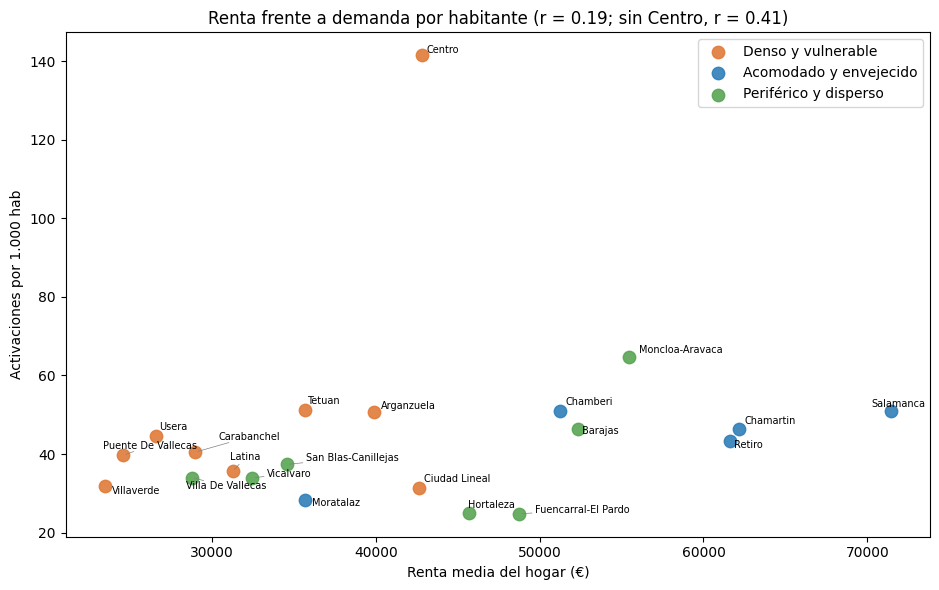

Centro: 141 activaciones/1.000 hab, frente a una media de 45


In [16]:
fig, ax = plt.subplots(figsize=(9.5, 6))
for c in range(3):
    d = df[df.cluster == c]
    ax.scatter(d.renta_media_hogar, d.activaciones_por_1000hab, s=80, color=COLORES_C[c],
               label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax.text(r.renta_media_hogar, r.activaciones_por_1000hab,r.distrito.title(),fontsize=7))
from adjustText import adjust_text
np.random.seed(42)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_todos = df[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
sc = df[df.distrito != 'CENTRO']
r_sin = sc[['renta_media_hogar', 'activaciones_por_1000hab']].corr().iloc[0, 1]
ax.set_xlabel('Renta media del hogar (€)'); ax.set_ylabel('Activaciones por 1.000 hab')
ax.set_title(f'Renta frente a demanda por habitante (r = {r_todos:.2f}; sin Centro, r = {r_sin:.2f})')
ax.legend(); fig.tight_layout()
guarda(fig, '07_renta_vs_activaciones.png')
plt.show()
print(f'Centro: {df.loc[df.distrito=="CENTRO","activaciones_por_1000hab"].iloc[0]:.0f} activaciones/1.000 hab, '
      f'frente a una media de {df.activaciones_por_1000hab.mean():.0f}')

La asociación descriptiva demanda-renta es débil con 21 distritos (r=0,19) y cambia al retirar Centro (0,41). No demuestra ausencia de relación ni una ley sobre renta y emergencias. Centro es un mundo aparte (141 activaciones por 1.000 hab, el triple de la media): la hipótesis es que recoge demanda de visitantes y ocio nocturno, no solo de vecinos, pero estos datos no permiten confirmarlo.

### 7.3 Los distritos vulnerables sí tienen una tipología de emergencia distinta

Esta es la pregunta central del enunciado. Se cruza cada activación con la categoría corregida del catálogo de tipos.

guardado: graficos_cierre_9D/08_tipologia_por_grupo.png


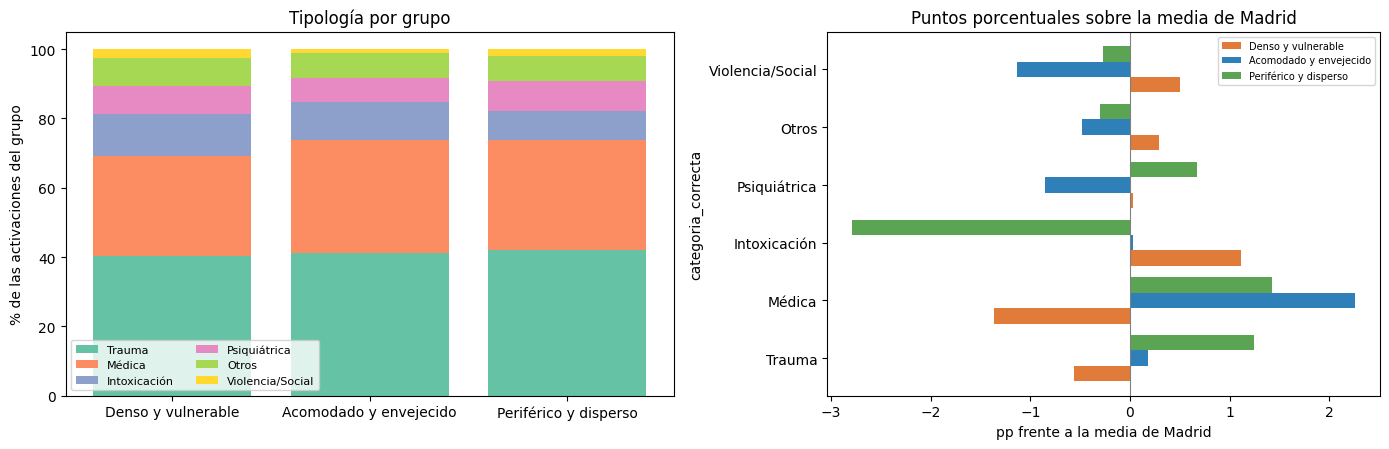

Mix por grupo (%), media de Madrid y diferencia en pp:
categoria_correcta      Trauma  Médica  Intoxicación  Psiquiátrica  Otros  Violencia/Social
Denso y vulnerable        40.3    29.0          12.1           8.0    7.9               2.7
Acomodado y envejecido    41.1    32.6          11.1           7.1    7.1               1.0
Periférico y disperso     42.1    31.8           8.2           8.7    7.3               1.9
MEDIA MADRID              40.9    30.3          11.0           8.0    7.6               2.2

Denso y vulnerable: Médica -1.4 pp; Intoxicación +1.1 pp; Trauma -0.6 pp
Acomodado y envejecido: Médica +2.3 pp; Violencia/Social -1.1 pp; Psiquiátrica -0.9 pp
Periférico y disperso: Intoxicación -2.8 pp; Médica +1.4 pp; Trauma +1.2 pp

Violencia/Social: 2.7% en el grupo denso y vulnerable frente a 1.0% en el acomodado.


In [17]:
mix = pd.crosstab(act.cluster if 'cluster' in act else act.distrito.map(dict(zip(df.distrito, df.cluster))),
                  act.categoria_correcta, normalize='index') * 100
mix.index = [nombres[i] for i in mix.index]
orden = ['Trauma', 'Médica', 'Intoxicación', 'Psiquiátrica', 'Otros', 'Violencia/Social']
mix = mix[orden]
glob = (act.categoria_correcta.value_counts(normalize=True) * 100)[orden]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.1, 1]})
bottom = np.zeros(3)
colcat = plt.get_cmap('Set2')
for i, categoriav in enumerate(orden):
    ax1.bar(mix.index, mix[categoriav], bottom=bottom, label=categoriav, color=colcat(i))
    bottom += mix[categoriav].to_numpy()
ax1.set_ylabel('% de las activaciones del grupo'); ax1.set_title('Tipología por grupo')
ax1.legend(fontsize=8, ncol=2)

dif_pp = (mix - glob).T
dif_pp.plot.barh(ax=ax2, color=[COLORES_C[0], COLORES_C[1], COLORES_C[2]], width=0.8)
ax2.axvline(0, color='grey', lw=0.8)
ax2.legend(fontsize=7)
ax2.set_title('Puntos porcentuales sobre la media de Madrid')
ax2.set_xlabel('pp frente a la media de Madrid')
fig.tight_layout()
guarda(fig, '08_tipologia_por_grupo.png')
plt.show()

print('Mix por grupo (%), media de Madrid y diferencia en pp:')
tabla_mix = mix.copy()
tabla_mix.loc['MEDIA MADRID'] = glob
print(tabla_mix.round(1).to_string())
print()
for nombre in mix.index:
    d = (mix.loc[nombre] - glob)
    top = d.reindex(d.abs().sort_values(ascending=False).index[:3])
    print(nombre + ': ' + '; '.join(f'{k} {v:+.1f} pp' for k, v in top.items()))
print(f"\nViolencia/Social: {mix.loc['Denso y vulnerable', 'Violencia/Social']:.1f}% en el grupo denso y vulnerable "
      f"frente a {mix.loc['Acomodado y envejecido', 'Violencia/Social']:.1f}% en el acomodado.")

guardado: graficos_cierre_9D/09_tipos_concretos_por_grupo.png


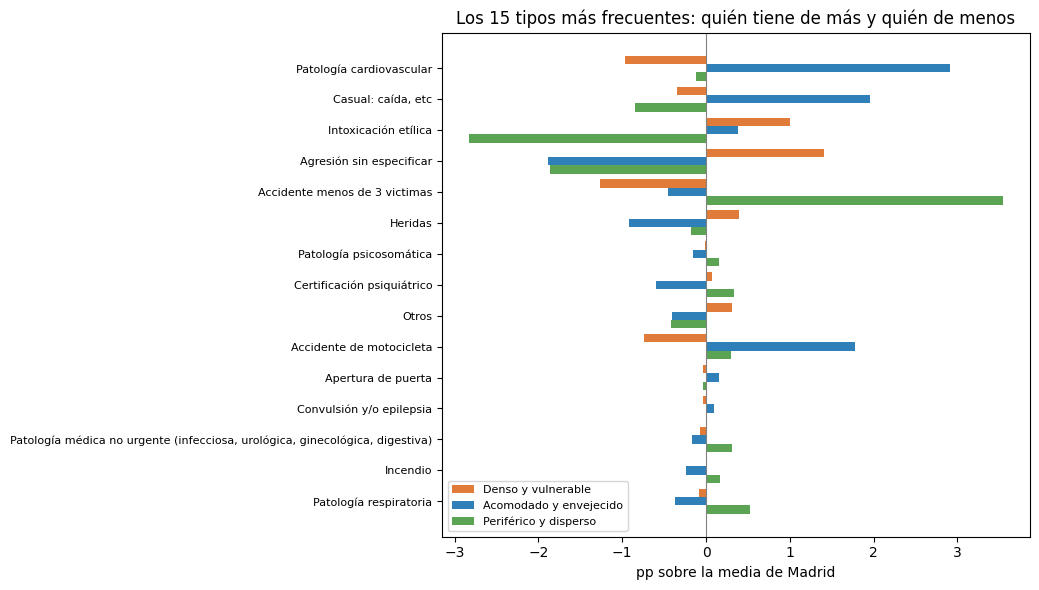

                                                                              Denso y vulnerable  Acomodado y envejecido  Periférico y disperso
tipo_emergencia                                                                                                                                
Patología cardiovascular                                                                    -1.0                     2.9                   -0.1
Casual: caída, etc                                                                          -0.3                     2.0                   -0.8
Intoxicación etílica                                                                         1.0                     0.4                   -2.8
Agresión sin especificar                                                                     1.4                    -1.9                   -1.9
Accidente menos de 3 victimas                                                               -1.3                    -0.5                

In [18]:
# Tipos concretos que más distinguen a cada grupo (pp sobre la media)
top15 = act.tipo_emergencia.value_counts().head(15).index
gr = pd.crosstab(act.distrito.map(dict(zip(df.distrito, df.cluster))), act.tipo_emergencia,
                 normalize='index')[top15] * 100
gr.index = [nombres[i] for i in gr.index]
gl = act.tipo_emergencia.value_counts(normalize=True)[top15] * 100
dift = (gr - gl).T
fig, ax = plt.subplots(figsize=(10.5, 6))
y = np.arange(len(dift)); h = 0.27
for i, nombre in enumerate(dift.columns):
    ax.barh(y + (i - 1) * h, dift[nombre], height=h, color=COLORES_C[i], label=nombre)
ax.set_yticks(y); ax.set_yticklabels(dift.index, fontsize=8); ax.invert_yaxis()
ax.axvline(0, color='grey', lw=0.8)
ax.set_xlabel('pp sobre la media de Madrid'); ax.set_title('Los 15 tipos más frecuentes: quién tiene de más y quién de menos')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '09_tipos_concretos_por_grupo.png')
plt.show()
print(dift.round(1).to_string())

**Tipología 9D:** la tabla precedente muestra categorías y tipos concretos por grupo y sus diferencias respecto a Madrid. Son composiciones observadas; se contrastan directamente renta/vulnerabilidad y tasas por distrito en 7.7-7.8, sin depender solo del nombre del clúster. Más prioridad de catálogo no es gravedad clínica medida.

### 7.4 Ritmo diario e intoxicaciones

guardado: graficos_cierre_9D/10_ritmo_diario_e_intoxicacion.png


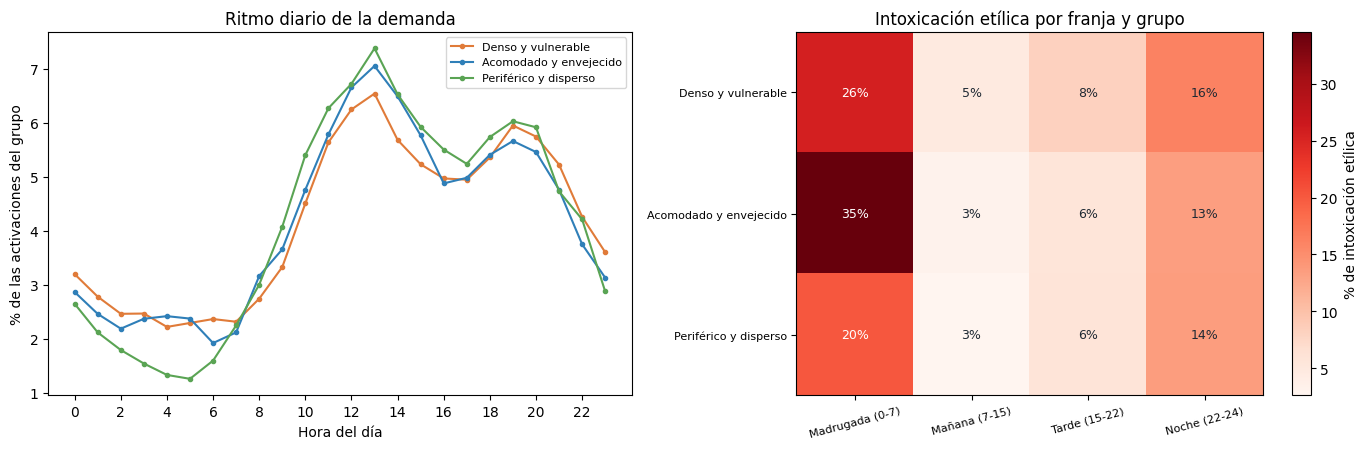

% de activaciones nocturnas (22-7 h), top 5:
distrito
CENTRO                32.2
CHAMBERI              29.1
TETUAN                25.9
USERA                 25.6
PUENTE DE VALLECAS    24.5


In [19]:
def franja(h):
    if pd.isna(h): return np.nan
    if 0 <= h < 7: return 'Madrugada (0-7)'
    if 7 <= h < 15: return 'Mañana (7-15)'
    if 15 <= h < 22: return 'Tarde (15-22)'
    return 'Noche (22-24)'
act['franja'] = act.hora.map(franja)
act['cluster_nombre'] = act.distrito.map(dict(zip(df.distrito, df.cluster_nombre)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
curvas = pd.crosstab(act.cluster_nombre, act.hora, normalize='index') * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax1.plot(range(24), curvas.loc[nombre, range(24)], marker='o', ms=3,
             color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax1.set_xlabel('Hora del día'); ax1.set_ylabel('% de las activaciones del grupo')
ax1.set_title('Ritmo diario de la demanda'); ax1.legend(fontsize=8); ax1.set_xticks(range(0, 24, 2))

intox = act[act.tipo_emergencia == 'Intoxicación etílica']
orden_f = ['Madrugada (0-7)', 'Mañana (7-15)', 'Tarde (15-22)', 'Noche (22-24)']
tot = pd.crosstab(act.cluster_nombre, act.franja)[orden_f]
ii = pd.crosstab(intox.cluster_nombre, intox.franja)[orden_f]
porc = (ii / tot * 100).loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
im = ax2.imshow(porc, cmap='Reds', aspect='auto')
ax2.set_xticks(range(4)); ax2.set_xticklabels(orden_f, fontsize=8, rotation=15)
ax2.set_yticks(range(3)); ax2.set_yticklabels(porc.index, fontsize=8)
for i in range(3):
    for j in range(4):
        ax2.text(j, i, f'{porc.to_numpy()[i, j]:.0f}%', ha='center', va='center', fontsize=9,
                 color='white' if porc.to_numpy()[i, j] > 20 else INK)
fig.colorbar(im, ax=ax2, label='% de intoxicación etílica')
ax2.set_title('Intoxicación etílica por franja y grupo')
fig.tight_layout()
guarda(fig, '10_ritmo_diario_e_intoxicacion.png')
plt.show()

noche = act.assign(n=act.hora.map(lambda h: pd.notna(h) and (h < 7 or h >= 22))).groupby('distrito').n.mean() * 100
print('% de activaciones nocturnas (22-7 h), top 5:')
print(noche.sort_values(ascending=False).head(5).round(1).to_string())

**Ritmo diario 9D:** se compara la distribución de activaciones dentro de cada grupo y el porcentaje de etílicas dentro de cada franja. No se deduce causa de ocio ni residencia del paciente. Las cifras del gráfico se recalculan con los 9/5/7 distritos principales.

### 7.5 Estacionalidad

guardado: graficos_cierre_9D/11_estacionalidad.png


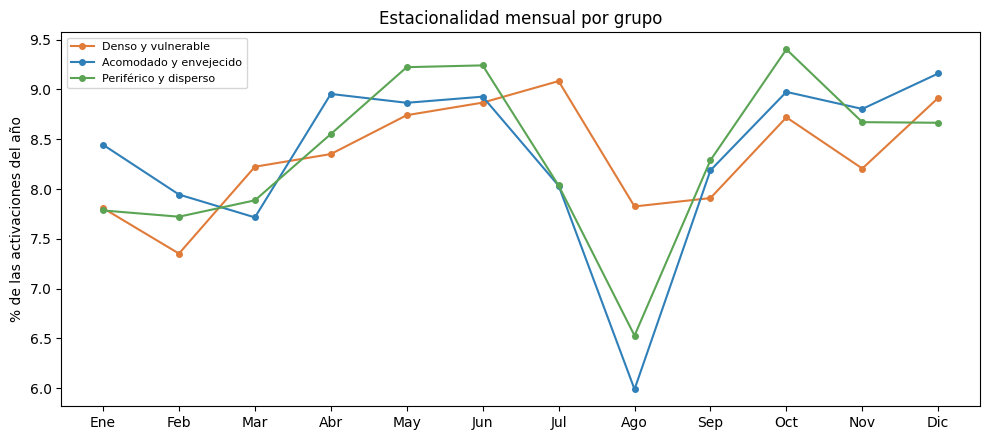

Media Madrid por mes (%):
mes
ENERO         7.9
FEBRERO       7.6
MARZO         8.0
ABRIL         8.5
MAYO          8.9
JUNIO         9.0
JULIO         8.6
AGOSTO        7.2
SEPTIEMBRE    8.1
OCTUBRE       8.9
NOVIEMBRE     8.4
DICIEMBRE     8.9


In [20]:
MESES = ['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'MAYO', 'JUNIO', 'JULIO', 'AGOSTO',
         'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE', 'DICIEMBRE']
fig, ax = plt.subplots(figsize=(10, 4.5))
mensual = pd.crosstab(act.cluster_nombre, act.mes)[MESES]
mensual = mensual.div(mensual.sum(axis=1), axis=0) * 100
for nombre in ['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']:
    ax.plot(range(12), mensual.loc[nombre], marker='o', ms=4,
            color=COLORES_C[{v: k for k, v in nombres.items()}[nombre]], label=nombre)
ax.set_xticks(range(12)); ax.set_xticklabels([m[:3].title() for m in MESES])
ax.set_ylabel('% de las activaciones del año'); ax.set_title('Estacionalidad mensual por grupo')
ax.legend(fontsize=8)
fig.tight_layout()
guarda(fig, '11_estacionalidad.png')
plt.show()
print('Media Madrid por mes (%):')
print((act.mes.value_counts()[MESES] / len(act) * 100).round(1).to_string())

**Estacionalidad 9D:** porcentajes calculados dentro de cada grupo sobre su año. Los valles no miden que se vacíe la población, y no prueban movilidad ni efecto del clima. Sin día no se distingue laborable de fin de semana.

### 7.6 Prioridad y oferta frente a demanda

guardado: graficos_cierre_9D/12_prioridad_y_oferta.png


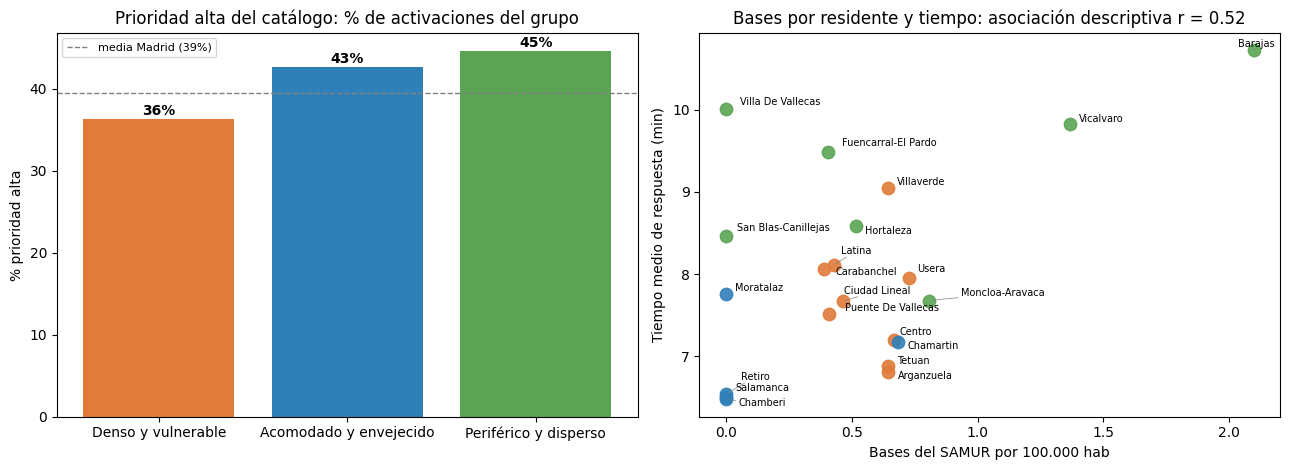

Activaciones anuales por base (media del grupo):
cluster_nombre
Acomodado y envejecido    6785.0
Denso y vulnerable        9251.0
Periférico y disperso     4723.0

Distritos sin base propia: Retiro, Salamanca, Chamberi, Moratalaz, Villa De Vallecas, San Blas-Canillejas


In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
pa = act.assign(p=(act.prioridad == 'alta')).groupby('cluster_nombre').p.mean() * 100
pa = pa.loc[['Denso y vulnerable', 'Acomodado y envejecido', 'Periférico y disperso']]
ax1.bar(pa.index, pa, color=[COLORES_C[i] for i in range(3)])
for i, v in enumerate(pa):
    ax1.text(i, v + 0.5, f'{v:.0f}%', ha='center', fontweight='bold', fontsize=10)
ax1.axhline((act.prioridad == 'alta').mean() * 100, color='grey', ls='--', lw=1,
            label=f"media Madrid ({(act.prioridad == 'alta').mean() * 100:.0f}%)")
ax1.set_ylabel('% prioridad alta'); ax1.set_title('Prioridad alta del catálogo: % de activaciones del grupo')
ax1.legend(fontsize=8)

df['bases_por_100k'] = df.num_bases_samur / df.poblacion * 1e5
for c in range(3):
    d = df[df.cluster == c]
    ax2.scatter(d.bases_por_100k, d.tiempo_respuesta_medio_min, s=80, color=COLORES_C[c],
                label=nombres[c], alpha=0.9)
texts = []
for _, r in df.iterrows():
    texts.append(ax2.text(r.bases_por_100k, r.tiempo_respuesta_medio_min,r.distrito.title(),fontsize=7))
np.random.seed(42)
adjust_text(texts, ax=ax2, arrowprops=dict(arrowstyle='-', color='grey', lw=.5))
r_oferta = df[['bases_por_100k', 'tiempo_respuesta_medio_min']].corr().iloc[0, 1]
ax2.set_xlabel('Bases del SAMUR por 100.000 hab'); ax2.set_ylabel('Tiempo medio de respuesta (min)')
ax2.set_title(f'Bases por residente y tiempo: asociación descriptiva r = {r_oferta:.2f}')
fig.tight_layout()
guarda(fig, '12_prioridad_y_oferta.png')
plt.show()

df['act_por_base'] = df.n_activaciones / df.num_bases_samur.replace(0, np.nan)
print('Activaciones anuales por base (media del grupo):')
print(df.groupby('cluster_nombre').act_por_base.mean().round(0).to_string())
print('\nDistritos sin base propia:', ', '.join(df[df.num_bases_samur == 0].distrito.str.title()))

**Prioridad y oferta 9D:** en medias distritales no ponderadas, el perfil periférico tiene 45,42% de tipos de prioridad alta, frente 36,53%denso y 42,32%acomodado. Es una mezcla típica por catálogo, no triaje clínico individual. El tiempo medio periférico es 9,25 min. Bases por residente y tiempo correlacionan r=+0,52 en 21 distritos, sin identificar causa. El promedio de cocientes activaciones/base entre distritos con base es 9251 en denso,6785 acomodado y 4723 periférico. No es carga real de cada base: las unidades se desplazan fuera de su distrito, y los distritos sin base se excluyen del cociente, no de la demanda. El gráfico de barras usa la proporción sobre todas las activaciones del grupo (ponderada por volumen), no la media distrital no ponderada de los perfiles.

### 7.7 Renta y tipos concretos de emergencia

Para comparar distritos de distinto tamaño, se calcula la tasa de cada tipo por 1.000 habitantes (`conteo del tipo / población × 1.000`), no el número bruto de activaciones. Se muestran Violencia/Social (categoría corregida del catálogo), Patología cardiovascular e Intoxicación etílica (tipos concretos). El gráfico compara estas tasas con `renta_media_hogar`; etiqueta los tres distritos con mayor tasa de cada tipo y muestra los 21 distritos. `r` es solo una correlación descriptiva. El denominador es la población residente, aunque las activaciones pueden incluir no residentes, especialmente en Centro. Hay 21 distritos: no se interpreta como prueba estadística ni causalidad.


guardado: graficos_cierre_9D/13_renta_vs_tipos_emergencia.png
Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:
  Violencia/Social: r = -0.59
  Patología cardiovascular: r = 0.34
  Intoxicación etílica: r = 0.13


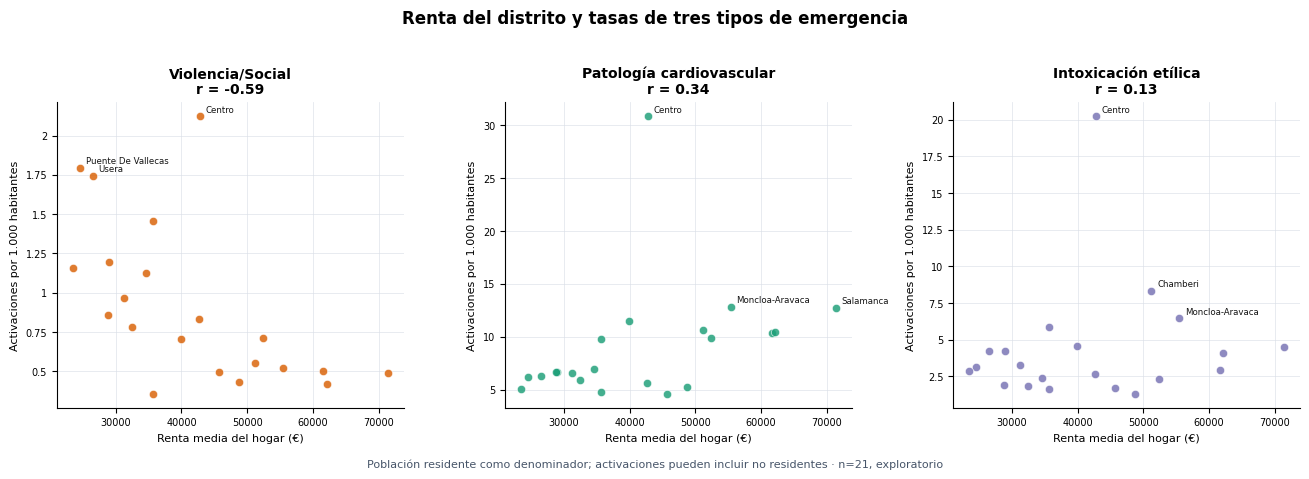

In [22]:
# Tasas distritales comparables: normalizar por población evita confundir volumen con tasa.
comparaciones = {
    'Violencia/Social': act.categoria_correcta.eq('Violencia/Social'),
    'Patología cardiovascular': act.tipo_emergencia.eq('Patología cardiovascular'),
    'Intoxicación etílica': act.tipo_emergencia.eq('Intoxicación etílica'),
}
base_renta = df.set_index('distrito')[['renta_media_hogar', 'poblacion']].copy()
conteos = pd.DataFrame({nombre: act.loc[mascara].groupby('distrito').size()
                        for nombre, mascara in comparaciones.items()})
conteos = conteos.reindex(base_renta.index, fill_value=0)
tasas = conteos.div(base_renta['poblacion'], axis=0) * 1000

fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.4), sharex=True)
colores = ['#d95f02', '#1b9e77', '#7570b3']
correlaciones = []
for ax, (nombre, valores), color in zip(axes, tasas.items(), colores):
    x = base_renta['renta_media_hogar']
    r = pd.concat([x, valores.rename('tasa')], axis=1).corr().iloc[0, 1]
    correlaciones.append((nombre, r))
    ax.scatter(x, valores, s=35, color=color, alpha=.82, edgecolor='white', linewidth=.45, zorder=3)
    top = valores.nlargest(3).index
    for distrito in top:
        ax.annotate(distrito.title(), (x.loc[distrito], valores.loc[distrito]), fontsize=6.2,
                    alpha=.92, xytext=(4, 3), textcoords='offset points')
    ax.set_title(f'{nombre}\nr = {r:.2f}', fontsize=10, fontweight='bold')
    ax.set_ylabel('Activaciones por 1.000 habitantes', fontsize=8)
    ax.grid(axis='both', color='#d9dee7', linewidth=.6, alpha=.7, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(labelsize=7)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'))
    ax.set_xlabel('Renta media del hogar (€)', fontsize=8)
fig.suptitle('Renta del distrito y tasas de tres tipos de emergencia', fontsize=12, fontweight='bold', y=1.02)
fig.text(.5, -.02, 'Población residente como denominador; activaciones pueden incluir no residentes · n=21, exploratorio',
         ha='center', fontsize=8, color='#475569')
fig.tight_layout()
guarda(fig, '13_renta_vs_tipos_emergencia.png')
print('Correlaciones descriptivas renta-tasa por distrito (n=21), no inferenciales:')
for nombre, r in correlaciones:
    print(f'  {nombre}: r = {r:.2f}')
plt.show()


### 7.8 Vulnerabilidad y tipos: contraste directo por distrito

Los grupos se construyen con variables sociales y de servicio; diferencias entre grupos describen su composición, no validan de forma independiente el modelo. Para responder al enunciado sin usar solo el nombre de un clúster, se cruza directamente `indice_vulnerabilidad` con tasas por 1.000 residentes de cada categoría de emergencia. Se añade renta y densidad en la misma matriz para ver el patrón completo, no solo el resultado más llamativo. Son correlaciones descriptivas Pearson de 21 distritos: no ajustes por movilidad, edad ni exposición; renta y vulnerabilidad están muy correlacionadas, así que no se interpretan como efectos independientes. No hay inferencia a barrios ni pacientes.


guardado: graficos_cierre_9D/17_contexto_categorias_directo.png


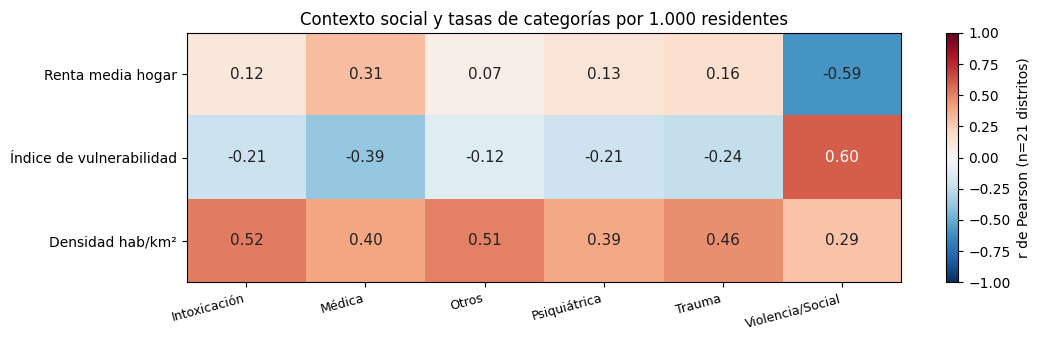

,Intoxicación,Médica,Otros,Psiquiátrica,Trauma,Violencia/Social
renta_media_hogar,0.116,0.311,0.066,0.127,0.163,-0.592
indice_vulnerabilidad,-0.212,-0.389,-0.122,-0.208,-0.238,0.602
densidad_hab_km2,0.521,0.398,0.507,0.385,0.465,0.286


categoria_correcta,Intoxicación,Médica,Otros,Psiquiátrica,Trauma,Violencia/Social
distrito,,,,,,
CENTRO,23.45,47.13,8.46,10.67,49.65,2.12
ARGANZUELA,5.09,17.10,3.76,4.22,19.73,0.70
RETIRO,3.40,15.10,3.22,3.31,17.70,0.50
SALAMANCA,4.96,17.43,3.64,3.36,21.06,0.49
CHAMARTIN,4.57,15.36,3.06,3.42,19.49,0.42
TETUAN,6.64,14.88,3.82,4.31,20.18,1.46
CHAMBERI,9.03,15.62,3.61,3.55,18.55,0.55
FUENCARRAL-EL PARDO,1.46,7.81,1.92,2.07,11.10,0.43
MONCLOA-ARAVACA,7.69,21.56,4.59,5.40,24.92,0.52


Renta-vulnerabilidad: -0.9556631675877348


In [23]:
cat_distrito=pd.crosstab(act.distrito,act.categoria_correcta).reindex(df.distrito,fill_value=0)
cat_distrito.index.name='distrito'
social=df.set_index('distrito')[['renta_media_hogar','indice_vulnerabilidad','densidad_hab_km2','poblacion']]
tasas_categoria=cat_distrito.div(social.poblacion,axis=0)*1000
correlacion_social=pd.DataFrame({c:{v:social[v].corr(tasas_categoria[c]) for v in ['renta_media_hogar','indice_vulnerabilidad','densidad_hab_km2']} for c in tasas_categoria})
fig,ax=plt.subplots(figsize=(11,3.5));im=ax.imshow(correlacion_social,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
ax.set_yticks(range(3));ax.set_yticklabels(['Renta media hogar','Índice de vulnerabilidad','Densidad hab/km²'])
ax.set_xticks(range(len(correlacion_social.columns)));ax.set_xticklabels(correlacion_social.columns,rotation=15,ha='right',fontsize=9)
for i in range(3):
    for k in range(len(correlacion_social.columns)):
        v=correlacion_social.iloc[i,k];ax.text(k,i,f'{v:.2f}',ha='center',va='center',color='white' if abs(v)>.6 else '#222',fontsize=11)
fig.colorbar(im,ax=ax,label='r de Pearson (n=21 distritos)');ax.set_title('Contexto social y tasas de categorías por 1.000 residentes')
fig.tight_layout();guarda(fig,'17_contexto_categorias_directo.png');plt.show()
display(correlacion_social.round(3));display(tasas_categoria.round(2))
print('Renta-vulnerabilidad:',social.renta_media_hogar.corr(social.indice_vulnerabilidad))


## 7.9 Con y sin edad registrada: comparación controlada

Se conserva el modelo 10D como baseline y se compara con 9D, retirando solo `edad_media_paciente`. No se eliminan registros ni `pct_mayores_65`. Se mantienen min-max,distancia,semilla 42,n_init 50,k candidatos 2..8 y misma rejilla DBSCAN. Se alinean etiquetas por máximo acuerdo solo para comparar nombres; no se fuerza ninguna asignación. Las siluetas internas describen cada representación y no son una prueba externa de superioridad. Se elige 9D como principal por prudencia interpretativa y se conserva 10D como baseline, con cambios, perfiles y contrapartidas de robustez explícitos.


Selección k comparable (cada silueta usa su espacio):


,modelo,k,inercia,silueta_kmeans,silueta_ward
0,Con edad (10D),2,10.7143,0.2370,0.2990
1,Con edad (10D),3,7.4303,0.2683,0.2619
2,Con edad (10D),4,6.1857,0.2138,0.2277
3,Con edad (10D),5,5.2271,0.2208,0.2267
4,Con edad (10D),6,4.2805,0.2120,0.1874
5,Con edad (10D),7,3.5640,0.2159,0.1867
6,Con edad (10D),8,3.0184,0.2068,0.1983
7,Sin edad (9D),2,9.7969,0.2511,0.3038
8,Sin edad (9D),3,6.6964,0.2747,0.2543
9,Sin edad (9D),4,5.5928,0.2349,0.2059


ARI entre alternativas: 0.7292418772563177


,distrito,renta_media_hogar,pct_mayores_65,edad_media_paciente,perfil10D,perfil9D,cambia
0,CENTRO,42831.0,22.1,50.07,Denso y vulnerable,Denso y vulnerable,False
1,ARGANZUELA,39876.0,18.5,49.27,Denso y vulnerable,Denso y vulnerable,False
2,RETIRO,61604.0,25.3,49.14,Acomodado y envejecido,Acomodado y envejecido,False
3,SALAMANCA,71432.0,26.8,49.33,Acomodado y envejecido,Acomodado y envejecido,False
4,CHAMARTIN,62145.0,25.2,49.02,Acomodado y envejecido,Acomodado y envejecido,False
5,TETUAN,35678.0,17.8,49.94,Denso y vulnerable,Denso y vulnerable,False
6,CHAMBERI,51234.0,23.5,49.49,Acomodado y envejecido,Acomodado y envejecido,False
7,FUENCARRAL-EL PARDO,48765.0,16.2,49.52,Periférico y disperso,Periférico y disperso,False
8,MONCLOA-ARAVACA,55432.0,19.8,49.07,Acomodado y envejecido,Periférico y disperso,True
9,LATINA,31245.0,20.5,49.55,Denso y vulnerable,Denso y vulnerable,False


Medias por perfil9D:


,renta_media_hogar,tasa_paro,indice_vulnerabilidad,pct_mayores_65,pct_extranjeros,densidad_hab_km2,activaciones_por_1000hab,pct_prioridad_alta,edad_media_paciente,tiempo_respuesta_medio_min
Denso y vulnerable,32867.222,12.767,0.593,18.100,20.522,18843.267,51.877,36.529,49.574,7.693
Acomodado y envejecido,56418.600,7.100,0.256,24.720,11.720,21956.680,43.930,42.324,49.130,6.892
Periférico y disperso,42572.571,10.143,0.436,15.929,14.886,3319.943,38.023,45.416,49.639,9.251


... (7 outputs left out)

,eps,min_samples,grupos,ruido,tamanos,silueta_sin_ruido
8,0.4,2,3,15,"2,2,2",0.539003
12,0.5,2,4,11,"2,3,3,2",0.396924
13,0.5,3,2,15,"3,3",0.348125
16,0.6,2,3,6,"10,3,2",0.389852
17,0.6,3,2,8,"10,3",0.442448


Silueta por distrito alternativa9D:


,distrito,silueta10D,silueta9D
0,CENTRO,0.155,0.143
1,ARGANZUELA,0.121,0.122
2,RETIRO,0.429,0.444
3,SALAMANCA,0.431,0.503
4,CHAMARTIN,0.453,0.476
5,TETUAN,0.324,0.330
6,CHAMBERI,0.128,0.210
7,FUENCARRAL-EL PARDO,0.242,0.295
8,MONCLOA-ARAVACA,0.148,-0.030
9,LATINA,0.362,0.320


guardado: graficos_cierre_9D/19_comparacion_con_sin_edad.png


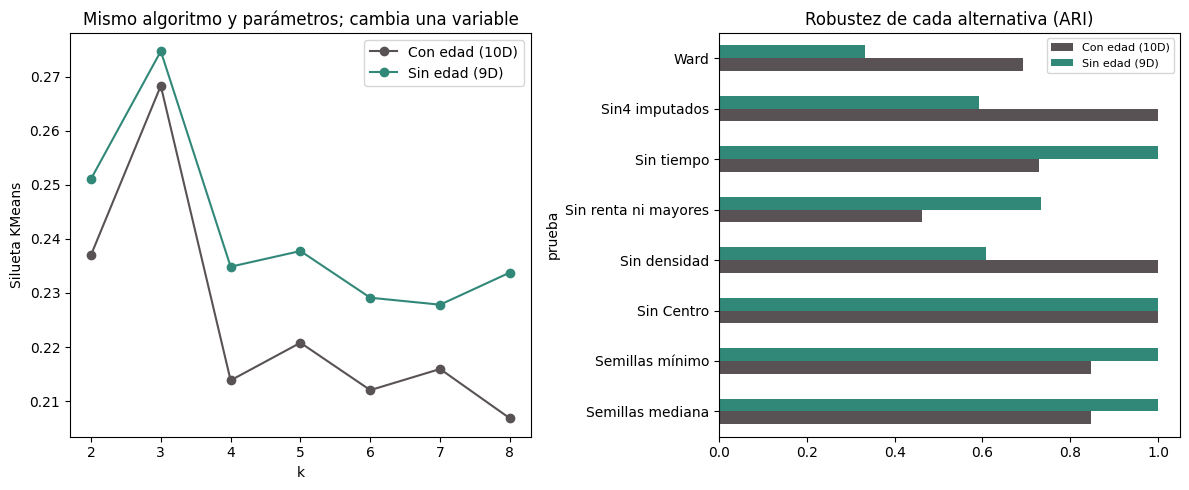

guardado: graficos_cierre_9D/20_dbscan_sin_edad.png


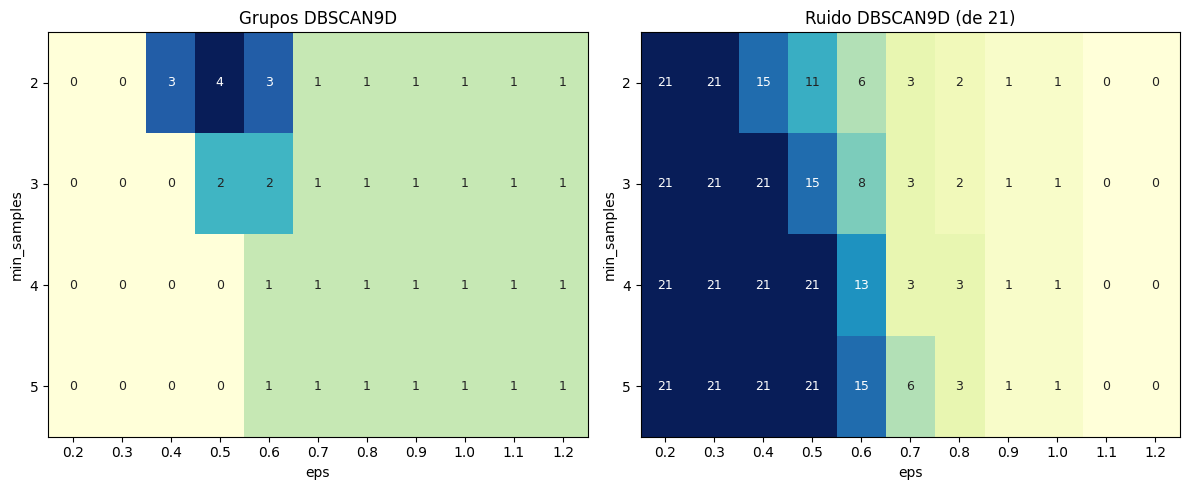

Perfil10D conservado como baseline:


,renta_media_hogar,tasa_paro,indice_vulnerabilidad,pct_mayores_65,pct_extranjeros,densidad_hab_km2,activaciones_por_1000hab,pct_prioridad_alta,edad_media_paciente,tiempo_respuesta_medio_min
Denso y vulnerable,33037.200,12.640,0.586,18.14,20.220,17689.910,50.426,37.309,49.509,7.770
Acomodado y envejecido,56254.167,7.183,0.255,23.90,11.633,18742.283,47.388,42.222,49.120,7.023
Periférico y disperso,41601.800,10.380,0.456,14.64,15.100,2651.920,32.822,46.374,49.896,9.724


DBSCAN10D: rejilla44 completa para contraste, no mezclar con tabla9D principal


,eps,min_samples,grupos,ruido,tamanos
0,0.2,2,0,21,
1,0.2,3,0,21,
2,0.2,4,0,21,
3,0.2,5,0,21,
4,0.3,2,0,21,
5,0.3,3,0,21,
6,0.3,4,0,21,
7,0.3,5,0,21,
8,0.4,2,2,17,"2,2"
9,0.4,3,0,21,


In [24]:
from itertools import permutations
variables10=['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros', 'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
X10=nrm[variables10].to_numpy()
labels10=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(X10)
variables9=[v for v in variables10 if v!='edad_media_paciente']
X9=nrm[variables9].to_numpy()
lab9_raw=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(X9)
mejor=max(permutations(range(3)),key=lambda perm:sum(np.array(perm)[lab9_raw]==labels10))
lab9=np.array(mejor)[lab9_raw]
comparativa_k=[]
for nombre,matriz in [('Con edad (10D)',X10),('Sin edad (9D)',X9)]:
    for k in range(2,9):
        kk=KMeans(n_clusters=k,n_init=50,random_state=42).fit(matriz)
        wh=AgglomerativeClustering(n_clusters=k,linkage='ward').fit_predict(matriz)
        comparativa_k.append(dict(modelo=nombre,k=k,inercia=kk.inertia_,silueta_kmeans=silhouette_score(matriz,kk.labels_),silueta_ward=silhouette_score(matriz,wh)))
comparativa_k=pd.DataFrame(comparativa_k)
print('Selección k comparable (cada silueta usa su espacio):');display(comparativa_k.round(4))
comparativa_distritos=df[['distrito','renta_media_hogar','pct_mayores_65','edad_media_paciente']].copy()
comparativa_distritos['perfil10D']=pd.Series(labels10,index=df.index).map(nombres)
comparativa_distritos['perfil9D']=pd.Series(lab9,index=df.index).map(nombres)
comparativa_distritos['cambia']=comparativa_distritos.perfil10D!=comparativa_distritos.perfil9D
print('ARI entre alternativas:',adjusted_rand_score(labels10,lab9));display(comparativa_distritos)
perfil9=df.groupby(lab9)[cols_desc].mean().round(3)
perfil9.index=perfil9.index.map(nombres)
print('Medias por perfil9D:');display(perfil9)
resumen9=df.assign(cluster9=lab9).groupby('cluster9').agg(distritos=('distrito','count'),activaciones=('n_activaciones','sum'))
resumen9['pct_activaciones']=resumen9.activaciones/df.n_activaciones.sum()*100
print('Tamaños y pesos9D:');display(resumen9)
comparativa_robustez=[]
for nombre,matriz,labels,vv in [('Con edad (10D)',X10,labels10,variables10),('Sin edad (9D)',X9,lab9,variables9)]:
    aa=[adjusted_rand_score(labels,KMeans(n_clusters=3,n_init=50,random_state=s).fit_predict(matriz)) for s in range(1,20)]
    comparativa_robustez.extend([dict(modelo=nombre,prueba='Semillas mínimo',ARI=min(aa)),dict(modelo=nombre,prueba='Semillas mediana',ARI=np.median(aa))])
    for prueba,mascara in [('Sin Centro',mA),('Sin4 imputados',mB)]:
        ajust=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(matriz[mascara.to_numpy()])
        comparativa_robustez.append(dict(modelo=nombre,prueba=prueba,ARI=adjusted_rand_score(labels[mascara.to_numpy()],ajust)))
    for prueba,quitadas in [('Sin renta ni mayores',['renta_media_hogar','pct_mayores_65']),('Sin densidad',['densidad_hab_km2']),('Sin tiempo',['tiempo_respuesta_medio_min'])]:
        ajust=KMeans(n_clusters=3,n_init=50,random_state=42).fit_predict(nrm[[v for v in vv if v not in quitadas]].to_numpy())
        comparativa_robustez.append(dict(modelo=nombre,prueba=prueba,ARI=adjusted_rand_score(labels,ajust)))
    comparativa_robustez.append(dict(modelo=nombre,prueba='Ward',ARI=adjusted_rand_score(labels,AgglomerativeClustering(n_clusters=3).fit_predict(matriz))))
comparativa_robustez=pd.DataFrame(comparativa_robustez)
print('Robustez comparable:');display(comparativa_robustez.round(3))
db9=[]
for eps in np.round(np.arange(.2,1.21,.1),1):
    for ms in [2,3,4,5]:
        ll=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X9);gr=sorted(set(ll)-{-1});mask=ll!=-1
        db9.append(dict(eps=float(eps),min_samples=ms,grupos=len(gr),ruido=int((ll==-1).sum()),tamanos=','.join(str(int((ll==g).sum())) for g in gr),silueta_sin_ruido=float(silhouette_score(X9[mask],ll[mask])) if len(gr)>=2 and mask.sum()>len(gr) else np.nan))
db9=pd.DataFrame(db9);print('Rejilla DBSCAN9D completa:');display(db9)
print('Multigrupo9D:');display(db9[db9.grupos>=2])
from sklearn.metrics import silhouette_samples
sil9=silhouette_samples(X9,lab9)
print('Silueta por distrito alternativa9D:');display(pd.DataFrame({'distrito':df.distrito,'silueta10D':silhouette_samples(X10,labels10),'silueta9D':sil9}).round(3))
# Visual comparison, aligned labels only for presentation, never manual reallocation.
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,5))
for nombre,color in [('Con edad (10D)','#585254'),('Sin edad (9D)','#318879')]:
    dd=comparativa_k[comparativa_k.modelo==nombre];ax1.plot(dd.k,dd.silueta_kmeans,'o-',label=nombre,color=color)
ax1.set(xlabel='k',ylabel='Silueta KMeans',title='Mismo algoritmo y parámetros; cambia una variable');ax1.legend()
cc=comparativa_robustez.pivot(index='prueba',columns='modelo',values='ARI');cc.plot.barh(ax=ax2,color=['#585254','#318879']);ax2.set(title='Robustez de cada alternativa (ARI)',xlim=(0,1.05));ax2.legend(fontsize=8)
fig.tight_layout();guarda(fig,'19_comparacion_con_sin_edad.png');plt.show()
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(12,5))
for ax,col,titulo in [(ax1,'grupos','Grupos DBSCAN9D'),(ax2,'ruido','Ruido DBSCAN9D (de 21)')]:
    tabla=db9.pivot(index='min_samples',columns='eps',values=col);im=ax.imshow(tabla,aspect='auto',cmap='YlGnBu');ax.set_xticks(range(len(tabla.columns)));ax.set_xticklabels(tabla.columns);ax.set_yticks(range(len(tabla.index)));ax.set_yticklabels(tabla.index);ax.set(xlabel='eps',ylabel='min_samples',title=titulo)
    for i in range(len(tabla)):
        for j in range(len(tabla.columns)):ax.text(j,i,str(tabla.iloc[i,j]),ha='center',va='center',fontsize=9,color='white' if tabla.iloc[i,j]>tabla.to_numpy().max()*.55 else '#222')
fig.tight_layout();guarda(fig,'20_dbscan_sin_edad.png');plt.show()
comparacion_export={'k':comparativa_k.to_dict('records'),'robustez':comparativa_robustez.to_dict('records'),'distritos':comparativa_distritos.to_dict('records'),'resumen9':resumen9.reset_index().to_dict('records'),'perfil9':perfil9.reset_index().to_dict('records'),'dbscan9':db9.fillna('').to_dict('records'),'ari10vs9':adjusted_rand_score(labels10,lab9),'variables9':variables9,'silueta9':float(silhouette_score(X9,lab9))}
(carpeta/'comparacion_edad.json').write_text(json.dumps(comparacion_export,ensure_ascii=False,indent=2))

print('Perfil10D conservado como baseline:');display(df.groupby(labels10)[cols_desc].mean().rename(index=nombres).round(3))
print('DBSCAN10D: rejilla44 completa para contraste, no mezclar con tabla9D principal')
db10=[]
for eps in np.round(np.arange(.2,1.21,.1),1):
    for ms in [2,3,4,5]:
        ll=DBSCAN(eps=float(eps),min_samples=ms).fit_predict(X10);gr=sorted(set(ll)-{-1})
        db10.append(dict(eps=eps,min_samples=ms,grupos=len(gr),ruido=int((ll==-1).sum()),tamanos=','.join(str(int((ll==g).sum())) for g in gr)))
display(pd.DataFrame(db10))


**Lectura comparada, sin escoger por una sola métrica.** KMeans k 3 es el mejor k ensayado en ambas representaciones: silueta 0,2683 con edad y 0,2747 sin edad. La diferencia es pequeña, y comparar siluetas entre espacios distintos no valida superioridad. Se mantienen 19 distritos; Moncloa-Aravaca pasa del perfil acomodado al periférico, y San Blas-Canillejas del denso al periférico. ARI entre alternativas=0,729. Sin edad, los perfiles son 9/5/7 distritos y 57,0%/20,0%/23,0% del servicio, respectivamente. El perfil acomodado sigue teniendo mayor porcentaje de residentes mayores 65(24,72%, frente 18,10% y 15,93%), sin usar edad del paciente para ese nombre.

La robustez es mixta: sin edad se estabiliza el arranque(ARI1,00 en 19 semillas frente 0,848), pero hay más sensibilidad al retirar los 4 distritos imputados(0,593 frente 1), al usar Ward(0,331 frente 0,692) y al retirar densidad(0,608 frente 1). Sin tiempo el modelo 9D no cambia; sin renta/mayores su ARI es 0,733. DBSCAN9D tiene 5 configuraciones multigrupo, siempre 6..15 de 21 distritos como ruido; sigue sin una partición multigrupo completa en la rejilla ensayada. La decisión metodológica es no usar la edad registrada para decidir perfiles por su interpretación no verificada y su amplificación min-max, pero no afirmar que 9D sea mejor en toda prueba. Se conserva 10D como comparación y se separan sus cifras de 9D.


## 8. Conclusiones del modelo principal 9D

Se agrupan 21 distritos en perfiles exploratorios de contexto y servicio. El grupo denso reúne 9 distritos y 57,0%del servicio; el acomodado 5 y 20,0%; el periférico 7 y 23,0%. No se infiere riesgo individual ni cobertura operativa. El perfil acomodado se llama envejecido por 24,72%mayores 65 residentes, no por edad del paciente.

La vulnerabilidad se asocia descriptivamente con tasa Violencia/Social(r=+0,602), y renta r=-0,592; renta y vulnerabilidad son muy correlacionadas entre sí(-0,956). La densidad se asocia al tiempo(r=-0,87), no demuestra influencia causal ni tiempo de viaje a base. Hay datos temporales ausentes y 21 observaciones; no validación externa.

Se elige 9D por prudencia al retirar edad registrada de interpretación dudosa, manteniendo 10D como comparación. Las 19 semillas son estables, pero quitar imputados o cambiar a Ward mueve fronteras. La diferencia de silueta es pequeña y no basta por sí sola para elegir. No se fuerza conservar los grupos antiguos. Catálogos hospitalarios no homogéneos y unidades ambiguas quedan fuera del modelo sin imputación.

## 9. Reproducibilidad

Ejecutar desde raíz o carpeta 1_3_clustering, después de las limpiezas y cruces. Entradas CSV intactas salvo catálogo hospitalario/cruces aprobados. Semilla 42,n_init 50,distancia euclídea,escalado min-max. Figuras principales en graficos_cierre_9D; comparación 10D queda separada. El mapa usa límites oficiales. Asserts comprueban identidad distrital, escalado y datos finitos.

In [25]:
# Resumen verificable para documentación y presentación: sin añadir entradas al modelo.
resumen={'variables':variables,'distritos':df.distrito.tolist(),'labels':df.cluster.astype(int).tolist(),'silueta':float(silhouette_score(X,df.cluster)),'siluetas':siluetas.to_dict(orient='records'),'tiempos':tiempos.reset_index().to_dict(orient='records'),'dbscan':dbscan_pruebas.to_dict(orient='records'),'cluster_totales':df.groupby('cluster').n_activaciones.sum().to_dict(),'n_activaciones':len(act)}
(carpeta/'verificacion_resultados.json').write_text(json.dumps(resumen,ensure_ascii=False,indent=2))
print('Resultado derivado de verificación guardado.')


Resultado derivado de verificación guardado.


## 10. Comprobación del enunciado y alcance de la evidencia

|Requisito|Evidencia ejecutada en este notebook|Qué no demuestra|
|---|---|---|
|Cruzar contexto social con activaciones|21 x 9, joins por distrito,145.966 activaciones con distrito, asserts e indicadores|No enlace paciente-censo individual|
|Agrupar distritos por riesgo/contexto|K-means k 3, perfiles reales, mapa y siluetas individuales|No riesgo clínico individual ni fronteras administrativas nuevas|
|Renta y tipos de emergencia|Tasas concretas por 1.000 residentes y matriz directa de categorías|No efecto independiente de renta|
|Vulnerabilidad y tipos|Matriz directa índice-categorías y mezcla por grupos|No inferencia a barrios ni efecto causal|
|Densidad y tiempos|Scatter distrital r=-0,87; mediana/P90 con faltantes|El campo es intervención menos solicitud, no trayecto de vuelta a base ni tiempo desde base verificado|
|Escalado|Min-max recalculado, tolerancia de redondeo, matriz finita|Igualar rangos no decide pesos ni elimina correlación|
|Reducción dimensional|PCA2D con varianza explicada impresa y ejes; mapa de correlación elimina redundancias|PCA solo visualiza; pierde varianza y no calcula los clústeres finales|
|Algoritmo alternativo|Ward y 44 configuraciones DBSCAN con grupos/ruido/tamaños|No ranking universal de algoritmos|

Cada decisión anterior está ligada a tablas, pruebas o fuentes. Las exclusiones son decisiones cerradas del análisis y las limitaciones permanecen visibles. No se afirma causalidad, validación estadística ni ahorro medido.
